<div align="center">

# **ML پروژه**
## **نیلوفر محمودی 402102392**
## **استاد شمس الهی**
</div>

<div align="right">

## بخش اول: طبقه بندی

 آیا می‌ توان دانش آموزانی را که احتمالا در پایان نرم عملکرد ضعیفی خواهند داشت، زودتر شناسایی کرد؟ 

$$
Risk =
\begin{cases}
1 & G3 < 10 \\
0 & G3 \ge 10
\end{cases}
$$


</div>

In [1]:
from pathlib import Path
from itertools import product
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef
)
from sklearn.metrics import precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from sklearn.metrics import brier_score_loss
from sklearn.inspection import (permutation_importance)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 392  #سه رقم آخر شماره دانشجوییمه
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 120,"savefig.dpi": 220})

<div  align="right">

## پرسش 1
</div>

<div align = "right">

بارگذاری جداگانه داده های ریاضی و پرتغالی و ساخت برچسب 
</div> 

    Course  Rows  Columns  At_risk  Not_at_risk Risk_rate  Missing_values
      Math   395       33      130          265    0.3291               0
Portuguese   649       33      100          549    0.1541               0


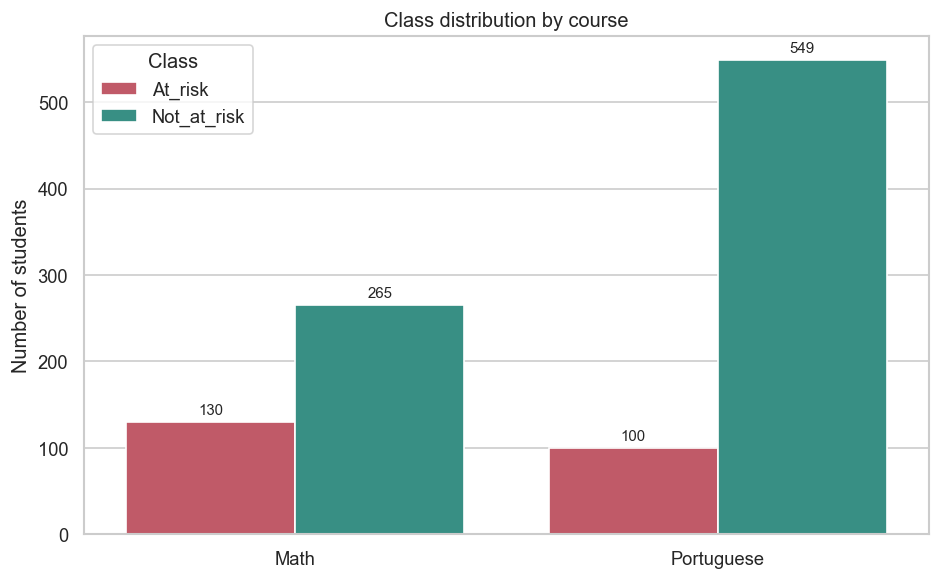

In [2]:
def find_file(filename):
    candidates = [
        Path.cwd() / filename,
        Path.cwd()/ "upload" / filename,
        Path("/mnt/data") / filename,
        Path.cwd().parent /filename,
    ]
    for path in candidates:
        if path.exists():
            return path

datasets = {
    "Math": pd.read_csv(find_file("student-mat.csv"),sep=";"),
    "Portuguese":pd.read_csv(find_file("student-por.csv"), sep=";"),
}

for course, frame in datasets.items():
    for grade in ["G1","G2","G3"]:
        frame[grade] = pd.to_numeric(frame[grade],errors="raise")
    frame["Risk"] =(frame["G3"]< 10).astype(int)
view_rows = []
for course, frame in datasets.items():
    view_rows.append({
        "Course":course,"Rows": len(frame),"Columns": frame.shape[1]- 1,
        "At_risk":int(frame["Risk"].sum()), "Not_at_risk": int((frame["Risk"] == 0).sum()),
        "Risk_rate": frame["Risk"].mean(),"Missing_values": int(frame.isna().sum().sum()),
    })
overview =pd.DataFrame(view_rows)
print(overview.to_string(index=False, formatters={"Risk_rate": "{:.4f}".format}))
distribution = overview.melt(id_vars="Course",value_vars=["At_risk", "Not_at_risk"],var_name="Class",value_name="Count",)
plt.figure(figsize=(8,5))
ax= sns.barplot(data=distribution, x="Course", y="Count", hue="Class", palette=["#D1495B", "#2A9D8F"])
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=9)
ax.set_title("Class distribution by course")
ax.set_xlabel("")
ax.set_ylabel("Number of students")
plt.tight_layout()
plt.show()

<div align = "right">

تعریف سناریوها، پیش پردازش، مدل ها و معیارهای ارزیابی
</div>

In [3]:
SCENARIOS = {
    "T0": {"drop":["G1", "G2"], "description": "Start of term"},
    "T1":{"drop": ["G2"], "description": "After G1"},
    "T2": {"drop":[], "description": "After G2"},
}

def flexible_split(target, seed=RANDOM_STATE):
    target = np.asarray(target)
    positions = np.arange(len(target))
    train_pos,temp_pos = train_test_split(positions, test_size=0.40, stratify=target, random_state=seed)
    validation_pos,test_pos = train_test_split(temp_pos, test_size=0.50, stratify=target[temp_pos], random_state=seed)
    return train_pos, validation_pos, test_pos

def scenario_xy(frame, scenario):
    drops =["G3", "Risk"] +SCENARIOS[scenario]["drop"]
    existing_drops= [column for column in drops if column in frame.columns]
    X = frame.drop(columns=existing_drops)
    y = frame["Risk"].copy() if "Risk" in frame.columns else None
    return X, y

def preprocessor(X):
    categorical= X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
    numeric =[column for column in X.columns if column not in categorical]
    return ColumnTransformer(
        transformers=[
            ("num",StandardScaler(), numeric),
            ("cat",OneHotEncoder(handle_unknown="ignore",sparse_output=False), categorical),
        ],
        remainder="drop",
    )

def candidate_models():
    candidates =[]
    for C in [0.1,1, 10]:
        candidates.append((
            "Logistic Regression",
            {"C":C},
            LogisticRegression(C=C, class_weight="balanced", max_iter=4000, solver="liblinear", random_state=RANDOM_STATE,),
        ))
    for max_depth, min_leaf in product([None, 10], [1,4]):
        candidates.append((
            "Random Forest",
            {"max_depth": max_depth, "min_samples_leaf": min_leaf},
            RandomForestClassifier(n_estimators=250, max_depth=max_depth, min_samples_leaf=min_leaf, class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=1),
        ))
    for C, gamma in product([0.5,2], ["scale","auto"]):
        candidates.append((
            "RBF SVM",
            {"C": C, "gamma": gamma},
            SVC(C=C,gamma=gamma,kernel="rbf",class_weight="balanced",probability=False,random_state=RANDOM_STATE,),
        ))
    return candidates

def probability_of_risk(model, X):
    if hasattr(model,"predict_proba"):
        return model.predict_proba(X)[:,1]
    scores= model.decision_function(X)
    return 1.0/ (1.0+np.exp(-scores))

def calculate_all_metrics(y_true, y_predict, y_probability):
    y_true =np.asarray(y_true,dtype=int)
    y_predict= np.asarray(y_predict, dtype=int)
    y_probability = np.asarray(y_probability,dtype=float)
    tn,fp,fn, tp =confusion_matrix(y_true, y_predict, labels=[0, 1]).ravel()
    roc_auc= roc_auc_score(y_true, y_probability) if np.unique(y_true).size == 2 else np.nan
    pr_auc =average_precision_score(y_true, y_probability) if np.any(y_true == 1) else np.nan
    return {
        "Accuracy": accuracy_score(y_true,y_predict),"Balanced_Accuracy": balanced_accuracy_score(y_true, y_predict),
        "Precision":precision_score(y_true, y_predict, zero_division=0),
        "Recall":recall_score(y_true, y_predict, zero_division=0),
        "Specificity": tn / (tn+ fp) if (tn+ fp) else np.nan,
        "F1": f1_score(y_true, y_predict,zero_division=0),
        "ROC_AUC": roc_auc,"PR_AUC":pr_auc,
        "MCC": matthews_corrcoef(y_true, y_predict),
        "False_Negative_Rate":fn / (fn + tp) if (fn + tp) else np.nan,
        "TN":int(tn),"FP": int(fp),"FN": int(fn),"TP":int(tp),
    }
def validation_rank(metrics):
    def safe_value(value):
        return -np.inf if pd.isna(value) else float(value)
    return (safe_value(metrics["F1"]),safe_value(metrics["Balanced_Accuracy"]),safe_value(metrics["PR_AUC"]),safe_value(metrics["ROC_AUC"]),)

def train_and_evaluate_task(frame, target, task_name,course, splits=None,store_models=False):
    if splits is None:
        splits= flexible_split(target)
    train_pos, validation_pos, test_pos =splits
    result_rows = []
    prediction_rows= []
    model_store ={}
    for scenario in SCENARIOS:
        X, _= scenario_xy(frame, scenario) 
        y= pd.Series(np.asarray(target, dtype=int), index=frame.index, name=task_name)
        X_train, y_train = X.iloc[train_pos], y.iloc[train_pos]
        X_validation,Y_validation = X.iloc[validation_pos], y.iloc[validation_pos]
        X_test,y_test = X.iloc[test_pos], y.iloc[test_pos]
        best_hyperparameter_by_family = {}
        for family, parameters,estimator in candidate_models():
            pipeline = Pipeline([("preprocess", preprocessor(X_train)),("model", estimator),])
            pipeline.fit(X_train, y_train)
            validation_prediction= pipeline.predict(X_validation)
            validation_probability =probability_of_risk(pipeline,X_validation)
            validation_metrics= calculate_all_metrics(Y_validation,validation_prediction,validation_probability,)
            rank = validation_rank(validation_metrics)
            if (family not in best_hyperparameter_by_family or rank > best_hyperparameter_by_family[family]["rank"]):
                best_hyperparameter_by_family[family] = {"rank":rank, "pipeline": pipeline,"parameters":parameters,"validation_metrics": validation_metrics,}

        X_train_validation =pd.concat([X_train, X_validation],axis=0)
        y_train_validation= pd.concat([y_train, Y_validation], axis=0)
        for family,selected in best_hyperparameter_by_family.items():
            final_model =clone(selected["pipeline"])
            final_model.fit(X_train_validation, y_train_validation)
            test_prediction= final_model.predict(X_test)
            test_probability =probability_of_risk(final_model, X_test)
            test_metrics= calculate_all_metrics(y_test, test_prediction, test_probability)
            row = {
                "Task": task_name, "Course": course, "Scenario": scenario, "Model": family,
                "Selected_parameters": json.dumps(selected["parameters"], sort_keys=True),
            }
            for metric_name,metric_value in selected["validation_metrics"].items():
                row[f"Validation_{metric_name}"] =metric_value
            row.update(test_metrics)
            result_rows.append(row)
            if store_models:
                model_store[(course, scenario,family)] =final_model
            for position, actual, predicted, probability in zip(test_pos,y_test,test_prediction,test_probability,):
                prediction_rows.append({
                    "Course": course, "Scenario": scenario, "Model": family,
                    "Student_position": int(position), "Actual_Risk": int(actual),
                    "Predicted_Risk":int(predicted), "Risk_probability": float(probability),
                })
    return pd.DataFrame(result_rows),model_store, pd.DataFrame(prediction_rows)
def select_by_validation(result_table):
    ranking_columns = ["Course","Scenario","Validation_F1","Validation_Balanced_Accuracy","Validation_PR_AUC","Validation_ROC_AUC",]
    return (
        result_table.sort_values(ranking_columns,ascending=[True, True, False, False, False, False],na_position="last",)
        .groupby(["Course", "Scenario"], as_index=False)
        .first()
    )
course_splits = {course: flexible_split(frame["Risk"]) for course, frame in datasets.items()}

<div align = "right">
 انتخاب تنظیمات هر مدل با مجموعه اعتبارسنجی و ارزیابی نهایی روی آزمون

In [4]:
all_results= []
all_predictions =[]
trained_models_q1 ={}
for course,frame in datasets.items():
    target_q1= (frame["G3"] < 10).astype(int) 
    result,models,prediction_table =train_and_evaluate_task(
        frame=frame,target=target_q1,task_name="Risk_Threshold_10",
        course=course,splits=course_splits[course],
    )
    all_results.append(result)
    all_predictions.append(prediction_table)
    trained_models_q1.update(models)

q1_results_df= pd.concat(all_results, ignore_index=True)
q1_predictions_df = pd.concat(all_predictions, ignore_index=True)
display_columns = ["Course", "Scenario", "Model","Validation_F1","Validation_Balanced_Accuracy", "Accuracy", "Balanced_Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC",]
print(q1_results_df[display_columns].round(3).to_string(index=False))

    Course Scenario               Model  Validation_F1  Validation_Balanced_Accuracy  Accuracy  Balanced_Accuracy  Precision  Recall    F1  ROC_AUC  PR_AUC
      Math       T0 Logistic Regression          0.588                         0.677     0.633              0.628      0.457   0.615 0.525    0.697   0.618
      Math       T0       Random Forest          0.542                         0.665     0.684              0.607      0.526   0.385 0.444    0.721   0.565
      Math       T0             RBF SVM          0.533                         0.638     0.709              0.685      0.552   0.615 0.582    0.682   0.583
      Math       T1 Logistic Regression          0.727                         0.811     0.886              0.876      0.815   0.846 0.830    0.948   0.908
      Math       T1       Random Forest          0.687                         0.772     0.861              0.847      0.778   0.808 0.792    0.959   0.938
      Math       T1             RBF SVM          0.694          

In [5]:
best_by_scenario =select_by_validation(q1_results_df)
best_display = best_by_scenario[[
    "Course","Scenario","Model",
    "Validation_F1","Validation_Balanced_Accuracy","Validation_PR_AUC",
    "Accuracy","Balanced_Accuracy","Precision",
    "Recall","F1","ROC_AUC","PR_AUC",]].copy()
print(best_display.round(3).to_string(index=False))

    Course Scenario               Model  Validation_F1  Validation_Balanced_Accuracy  Validation_PR_AUC  Accuracy  Balanced_Accuracy  Precision  Recall    F1  ROC_AUC  PR_AUC
      Math       T0 Logistic Regression          0.588                         0.677              0.545     0.633              0.628      0.457   0.615 0.525    0.697   0.618
      Math       T1 Logistic Regression          0.727                         0.811              0.679     0.886              0.876      0.815   0.846 0.830    0.948   0.908
      Math       T2 Logistic Regression          0.842                         0.896              0.902     0.962              0.972      0.897   1.000 0.945    0.993   0.984
Portuguese       T0             RBF SVM          0.553                         0.761              0.695     0.831              0.798      0.469   0.750 0.577    0.854   0.583
Portuguese       T1       Random Forest          0.762                         0.873              0.807     0.923            

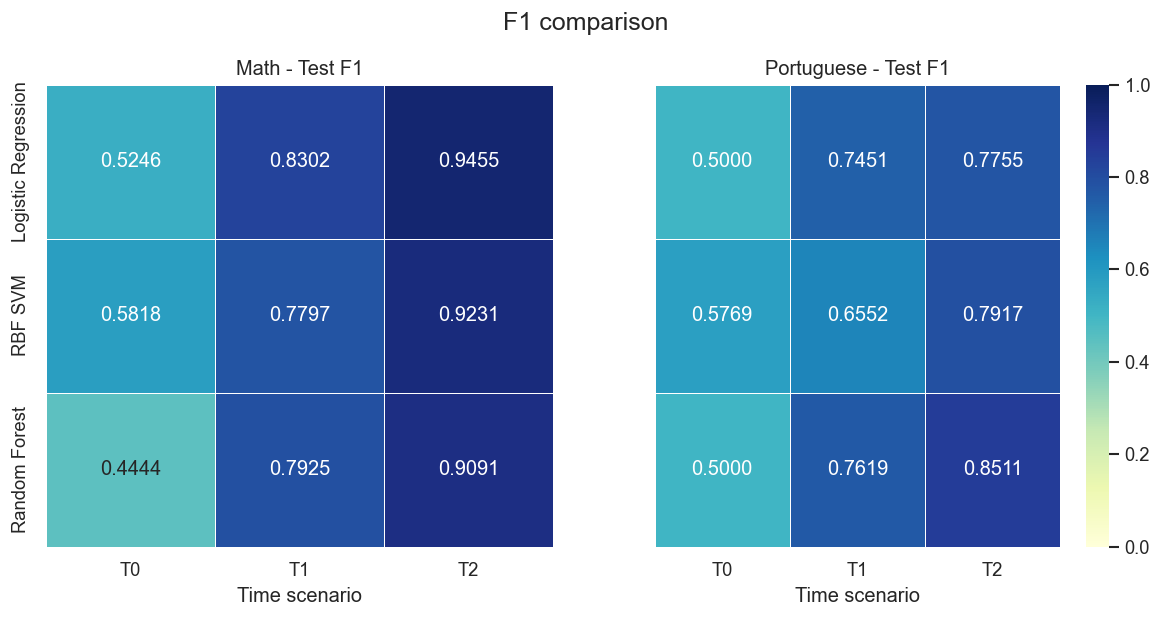

In [6]:
fig,axes= plt.subplots(1,2, figsize=(12,5), sharey=True)
for ax, course in zip(axes, ["Math", "Portuguese"]):
    pivot = (
        q1_results_df[q1_results_df["Course"]==course]
        .pivot(index="Model",columns="Scenario",values="F1")
        .reindex(columns=["T0","T1","T2"])
    )
    sns.heatmap(pivot,annot=True,fmt=".4f",cmap="YlGnBu",vmin=0,vmax=1,linewidths=0.5,cbar=(course == "Portuguese"),ax=ax,)
    ax.set_title(f"{course} - Test F1")
    ax.set_xlabel("Time scenario")
    ax.set_ylabel("")
fig.suptitle("F1 comparison",y=1.001,fontsize=15)
plt.show()

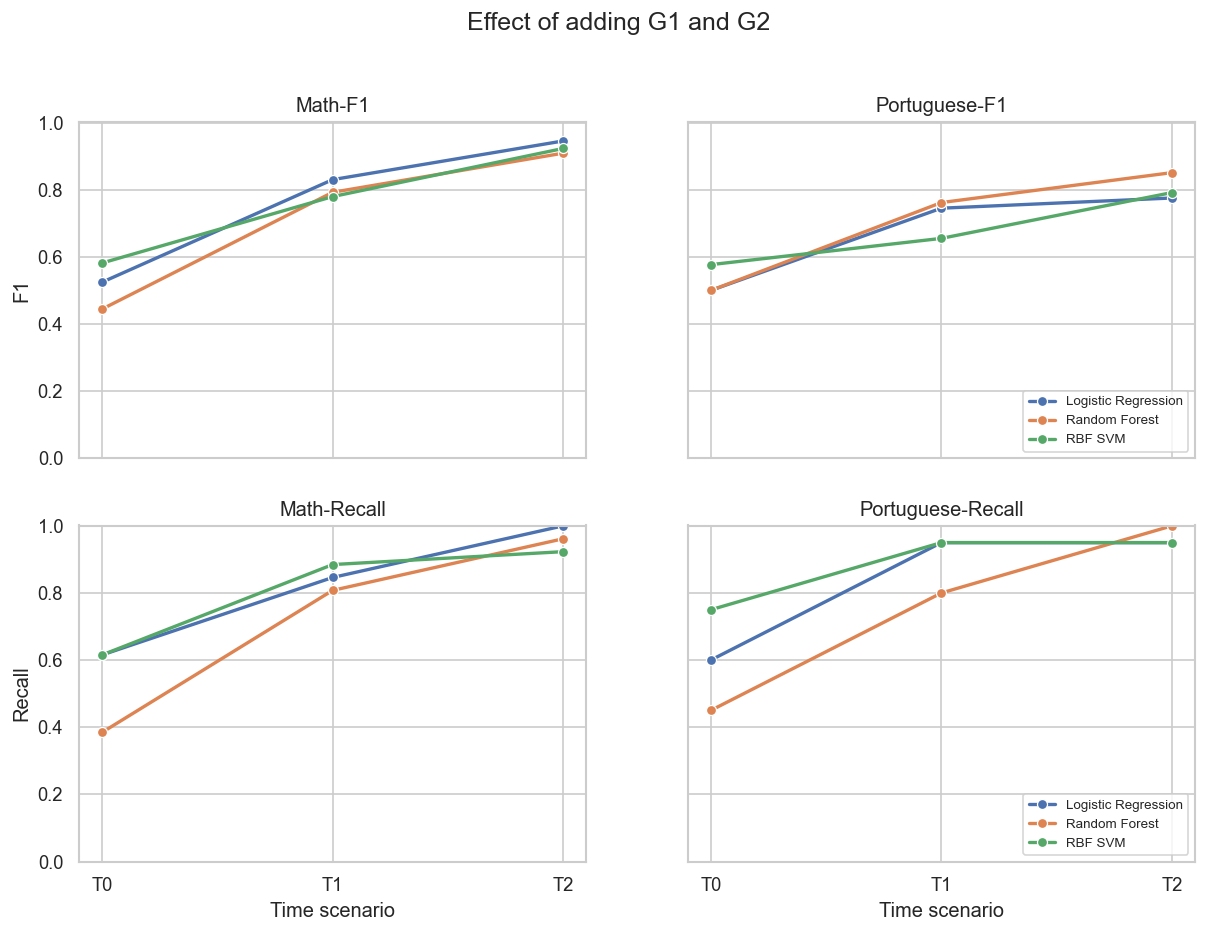

In [7]:
fig,axes = plt.subplots(2,2, figsize=(12,8),sharex=True, sharey="row")
for col,course in enumerate(["Math", "Portuguese"]):
    course_results = q1_results_df[q1_results_df["Course"] == course].copy()
    course_results["Scenario"] =pd.Categorical(course_results["Scenario"], ["T0", "T1", "T2"], ordered=True)
    course_results= course_results.sort_values("Scenario")
    for row,metric in enumerate(["F1","Recall"]):
        sns.lineplot(
            data=course_results,x="Scenario",y=metric,
            hue="Model",marker="o",linewidth=2,ax=axes[row, col],
        )
        axes[row,col].set_ylim(0, 1.001)
        axes[row, col].set_title(f"{course}-{metric}")
        axes[row,col].set_xlabel("Time scenario")
        if col== 1:
            axes[row, col].legend(loc="lower right",fontsize=8)
        else:
            axes[row, col].get_legend().remove()
fig.suptitle("Effect of adding G1 and G2",y=0.995,fontsize=15)
plt.show()

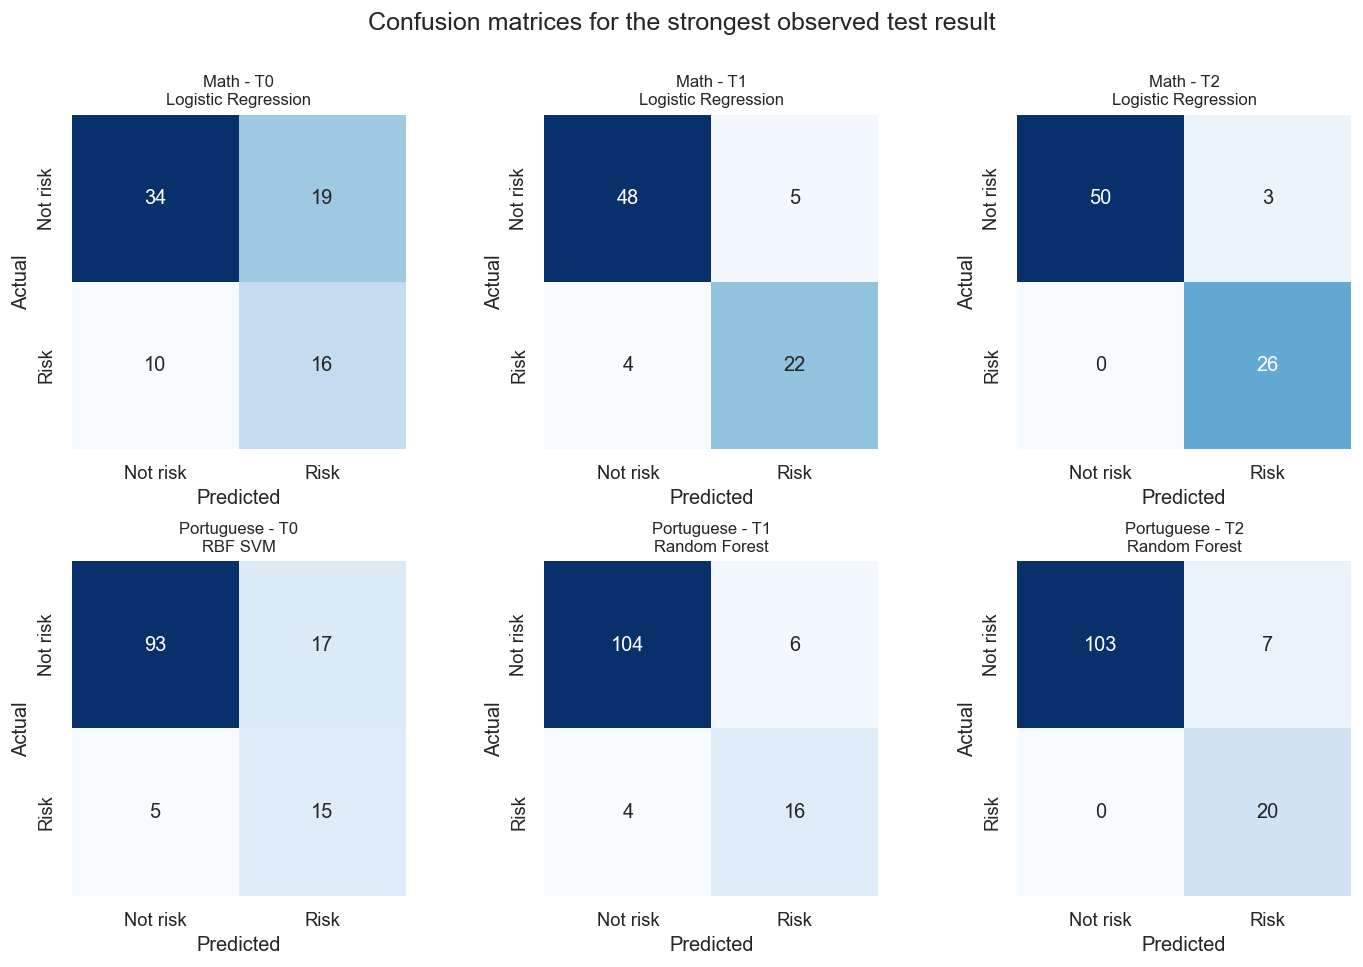

In [8]:
fig,axes = plt.subplots(2,3, figsize=(12,8))
for row,course in enumerate(["Math", "Portuguese"]):
    for col,scenario in enumerate(["T0", "T1", "T2"]):
        selected= best_by_scenario[(best_by_scenario["Course"] ==course) & (best_by_scenario["Scenario"]== scenario)].iloc[0]
        model_name= selected["Model"]
        model_data =q1_results_df[
            (q1_results_df["Course"]== course) & 
            (q1_results_df["Scenario"] ==scenario) & 
            (q1_results_df["Model"]== model_name)
        ].iloc[0]
        Confusion_matrix = np.array([
            [model_data["TN"],model_data["FP"]],
            [model_data["FN"], model_data["TP"]]
        ])
        sns.heatmap(
            Confusion_matrix, annot=True,fmt="d", cmap="Blues", cbar=False,
            square=True,xticklabels=["Not risk","Risk"],
            yticklabels=["Not risk","Risk"],ax=axes[row, col],
        )
        axes[row,col].set_title(f"{course} - {scenario}\n{model_name}", fontsize=10)
        axes[row, col].set_xlabel("Predicted")
        axes[row,col].set_ylabel("Actual") 
fig.suptitle("Confusion matrices for the strongest observed test result", y=1.001,fontsize=15)
plt.tight_layout()
plt.show()

<div  align="right">

## پرسش 2
</div>

In [9]:
baseline_rows = []
for course, frame in datasets.items():
    target = (frame["G3"] < 10).astype(int)
    train_pos, validation_pos, test_pos =course_splits[course]
    train_validation_target = target.iloc[np.concatenate([train_pos, validation_pos])]
    majority_class= int(train_validation_target.mode().iloc[0])
    training_risk_rate =train_validation_target.mean()
    y_test= target.iloc[test_pos].to_numpy()
    baseline_pred =np.full(len(test_pos),majority_class, dtype=int)
    baseline_prob= np.full(len(test_pos), training_risk_rate,dtype=float)
    for scenario in SCENARIOS:
        row ={"Task": "Risk_Threshold_10", "Course": course,"Scenario": scenario, "Model": "Majority Baseline", "Type": "Baseline",}
        row.update(calculate_all_metrics(y_test, baseline_pred, baseline_prob))
        baseline_rows.append(row)

q2_baseline= pd.DataFrame(baseline_rows)
q1_results_df["Type"] ="Model"
q2_selected= q1_results_df.merge(
    best_by_scenario[["Course", "Scenario", "Model"]], on=["Course", "Scenario", "Model"], how="inner",
)
q2_focus = pd.concat([q2_selected,q2_baseline], ignore_index=True).sort_values( ["Course", "Scenario", "Type", "Model"])
q2_focus["Accuracy_minus_Balanced_Accuracy"] = q2_focus["Accuracy"] - q2_focus["Balanced_Accuracy"]
print("Baseline vs Models for Q2:")
print(q2_focus[
    ["Course", "Scenario", "Type", "Model", "Accuracy", "Balanced_Accuracy", 
     "Precision","Recall", "F1","ROC_AUC", "PR_AUC", "MCC", "FN", "TP",]].round(3).to_string(index=False))

Baseline vs Models for Q2:
    Course Scenario     Type               Model  Accuracy  Balanced_Accuracy  Precision  Recall    F1  ROC_AUC  PR_AUC   MCC  FN  TP
      Math       T0 Baseline   Majority Baseline     0.671              0.500      0.000   0.000 0.000    0.500   0.329 0.000  26   0
      Math       T0    Model Logistic Regression     0.633              0.628      0.457   0.615 0.525    0.697   0.618 0.243  10  16
      Math       T1 Baseline   Majority Baseline     0.671              0.500      0.000   0.000 0.000    0.500   0.329 0.000  26   0
      Math       T1    Model Logistic Regression     0.886              0.876      0.815   0.846 0.830    0.948   0.908 0.745   4  22
      Math       T2 Baseline   Majority Baseline     0.671              0.500      0.000   0.000 0.000    0.500   0.329 0.000  26   0
      Math       T2    Model Logistic Regression     0.962              0.972      0.897   1.000 0.945    0.993   0.984 0.920   0  26
Portuguese       T0 Baseline   Majo

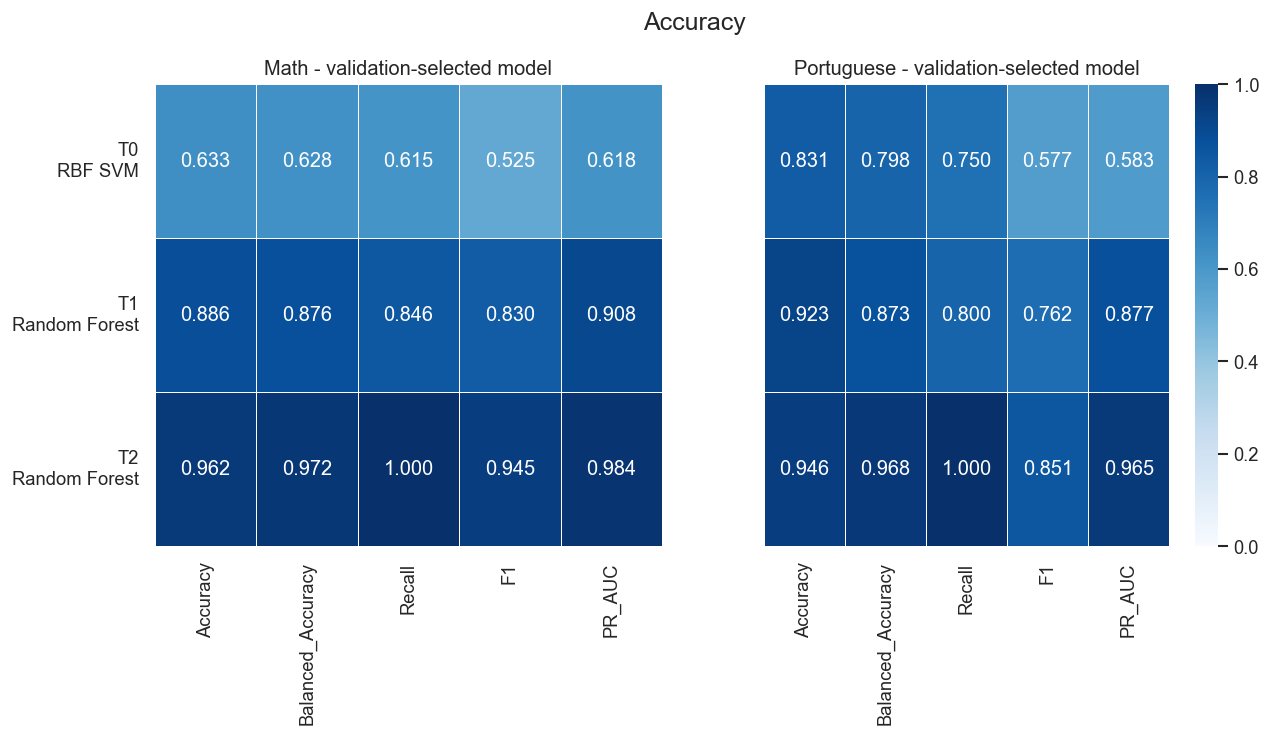

In [10]:
q2_metric_columns= ["Accuracy","Balanced_Accuracy", "Recall", "F1","PR_AUC"]
fig, axes = plt.subplots(1, 2, figsize=(12,5), sharey=True)
for ax,course in zip(axes,["Math","Portuguese"]):
    course_table = (
        q2_selected[q2_selected["Course"] == course]
        .set_index("Scenario")[q2_metric_columns]
        .reindex(["T0","T1","T2"])
    )
    sns.heatmap(
        course_table,annot=True, fmt=".3f", cmap="Blues",
        vmin=0, vmax=1, linewidths=0.5, cbar=(course == "Portuguese"), ax=ax,
    )
    selected_names = best_by_scenario[best_by_scenario["Course"] == course].set_index("Scenario")["Model"]
    ax.set_yticklabels([f"{scenario}\n{selected_names.loc[scenario]}" for scenario in ["T0", "T1", "T2"]], rotation=0)
    ax.set_title(f"{course} - validation-selected model")
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Accuracy", y=1.001, fontsize=15)
plt.show()

<div  align="right">

## پرسش 3
</div>

In [11]:
def bootstrap_metric(y_true, y_predict, y_probability,metrics, n_bootstrap, seed):
    y_true= np.asarray(y_true, dtype=int)
    y_predict= np.asarray(y_predict, dtype=int)
    y_probability =np.asarray(y_probability, dtype=float)
    rng =np.random.default_rng(seed)
    samples= {metric: [] for metric in metrics}
    for _ in range(n_bootstrap):
        sample_index= rng.integers(0,len(y_true), size=len(y_true))
        sampled_metrics= calculate_all_metrics(
            y_true[sample_index],
            y_predict[sample_index],
            y_probability[sample_index],
        )
        for metric in metrics:
            if np.isfinite(sampled_metrics[metric]):
                samples[metric].append(sampled_metrics[metric])
    point_metrics =calculate_all_metrics(y_true, y_predict, y_probability)
    rows=[]
    for metric in metrics:
        values=np.asarray(samples[metric], dtype=float)
        rows.append({
            "Metric": metric,"Estimate": point_metrics[metric],"CI_2.5": np.quantile(values,0.025),
            "CI_97.5":np.quantile(values, 0.975),"Bootstrap_valid_samples": len(values),
        })
    return rows

q3_metrics= ["Accuracy", "Balanced_Accuracy","Precision", "Recall", "Specificity", "F1","ROC_AUC", "PR_AUC"]
q3_rows= []
q3_selected_models ={}
for course_index,course in enumerate(["Math","Portuguese"]):
    selected_model= best_by_scenario[ (best_by_scenario["Course"] == course) &(best_by_scenario["Scenario"] == "T0")].iloc[0]["Model"]
    q3_selected_models[course] = selected_model
    selected_predictions = q1_predictions_df[(q1_predictions_df["Course"] == course) &(q1_predictions_df["Scenario"] == "T0") &(q1_predictions_df["Model"] == selected_model)].sort_values("Student_position")
    i_rows = bootstrap_metric(
        selected_predictions["Actual_Risk"],selected_predictions["Predicted_Risk"],selected_predictions["Risk_probability"],
        metrics=q3_metrics,n_bootstrap=2000,seed=RANDOM_STATE +100+course_index,
    )
    for row in i_rows:
        row.update({"Course": course, "Scenario":"T0", "Model": selected_model})
        q3_rows.append(row)
q3_reliability = pd.DataFrame(q3_rows)[["Course","Scenario","Model","Metric", "Estimate","CI_2.5", "CI_97.5", "Bootstrap_valid_samples"]]
print(q3_reliability.round(3).to_string(index=False))

    Course Scenario               Model            Metric  Estimate  CI_2.5  CI_97.5  Bootstrap_valid_samples
      Math       T0 Logistic Regression          Accuracy     0.633   0.532    0.734                     2000
      Math       T0 Logistic Regression Balanced_Accuracy     0.628   0.514    0.743                     2000
      Math       T0 Logistic Regression         Precision     0.457   0.297    0.622                     2000
      Math       T0 Logistic Regression            Recall     0.615   0.417    0.793                     2000
      Math       T0 Logistic Regression       Specificity     0.642   0.511    0.764                     2000
      Math       T0 Logistic Regression                F1     0.525   0.364    0.657                     2000
      Math       T0 Logistic Regression           ROC_AUC     0.697   0.558    0.825                     2000
      Math       T0 Logistic Regression            PR_AUC     0.618   0.442    0.774                     2000
Portuguese

    Course               Model  False_alarm_rate  Missed_risk_rate  False_alarms  Missed_at_risk
      Math Logistic Regression             0.358             0.385            19              10
Portuguese             RBF SVM             0.155             0.250            17               5


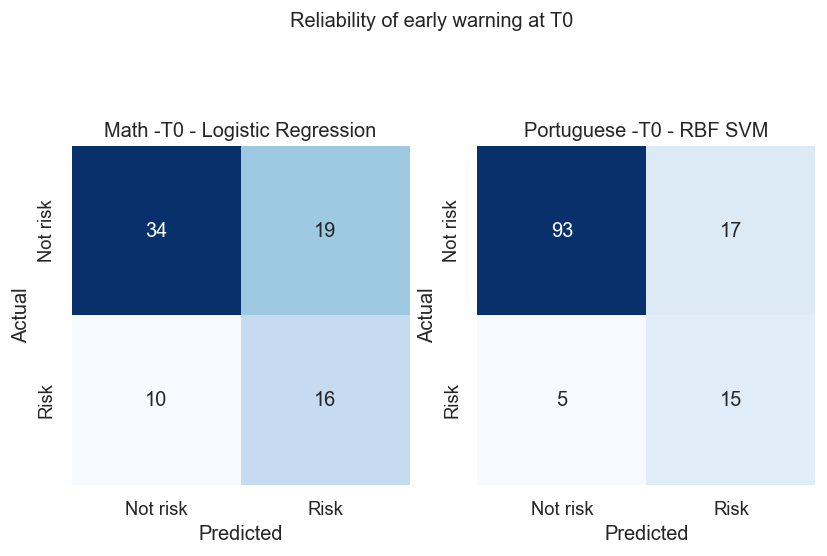

In [12]:
fig,axes = plt.subplots(1,2, figsize=(8,5))
q3_error_rows= []
for ax,course in zip(axes,["Math", "Portuguese"]):
    selected_model= q3_selected_models[course]
    model_data= q1_results_df[(q1_results_df["Course"] == course) & (q1_results_df["Scenario"] == "T0") & (q1_results_df["Model"] == selected_model)].iloc[0]
    TN,FP,FN,TP =model_data["TN"], model_data["FP"], model_data["FN"], model_data["TP"]
    q3_error_rows.append({
        "Course": course,"Model": selected_model,
        "False_alarm_rate": FP / (FP + TN) if (FP+ TN) else np.nan,
        "Missed_risk_rate":FN/ (FN +TP) if (FN +TP) else np.nan,
        "False_alarms":int(FP),"Missed_at_risk": int(FN),
    })
    Confusion_Matrix =np.array([[TN,FP], [FN,TP]])
    sns.heatmap(
        Confusion_Matrix,annot=True,fmt="d",cmap="Blues",
        cbar=False,square=True,
        xticklabels=["Not risk", "Risk"],yticklabels=["Not risk", "Risk"],ax=ax,
    )
    ax.set_title(f"{course} -T0 - {selected_model}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
q3_error_analysis =pd.DataFrame(q3_error_rows)
print(q3_error_analysis.round(3).to_string(index=False))
fig.suptitle("Reliability of early warning at T0", y=1.001, fontsize=12)
plt.show()

<div  align="right">

## پرسش 4
</div>

In [13]:
def scenario_delta_table(metric_table, before, after,metrics):
    before_rows= metric_table[metric_table["Scenario"] == before].set_index(["Course", "Model"])
    after_rows= metric_table[metric_table["Scenario"] ==after].set_index(["Course","Model"])
    delta = after_rows[metrics]- before_rows[metrics]
    delta= delta.reset_index()
    delta.insert(2,"Comparison", f"{after} - {before}")
    return delta

q4_metrics= ["Accuracy", "Balanced_Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]
q4_family_delta = scenario_delta_table(q1_results_df,"T0", "T1", q4_metrics)
print("Effect of adding G1 (T1 - T0) for all models:")
print(q4_family_delta.round(3).to_string(index=False))

Effect of adding G1 (T1 - T0) for all models:
    Course               Model Comparison  Accuracy  Balanced_Accuracy  Precision  Recall    F1  ROC_AUC  PR_AUC
      Math Logistic Regression    T1 - T0     0.253              0.247      0.358   0.231 0.306    0.250   0.290
      Math       Random Forest    T1 - T0     0.177              0.240      0.251   0.423 0.348    0.239   0.373
      Math             RBF SVM    T1 - T0     0.127              0.163      0.145   0.269 0.198    0.269   0.342
Portuguese Logistic Regression    T1 - T0     0.085              0.193      0.184   0.350 0.245    0.154   0.370
Portuguese       Random Forest    T1 - T0     0.062              0.180      0.165   0.350 0.262    0.113   0.311
Portuguese             RBF SVM    T1 - T0     0.015              0.091      0.031   0.200 0.078    0.116   0.306


Paired Delta (T1 - T0):
    Course Before After        Before_model         After_model            Metric  Before_estimate  After_estimate  Delta
      Math     T0    T1 Logistic Regression Logistic Regression          Accuracy            0.633           0.886  0.253
      Math     T0    T1 Logistic Regression Logistic Regression Balanced_Accuracy            0.628           0.876  0.247
      Math     T0    T1 Logistic Regression Logistic Regression         Precision            0.457           0.815  0.358
      Math     T0    T1 Logistic Regression Logistic Regression            Recall            0.615           0.846  0.231
      Math     T0    T1 Logistic Regression Logistic Regression                F1            0.525           0.830  0.306
      Math     T0    T1 Logistic Regression Logistic Regression           ROC_AUC            0.697           0.948  0.250
      Math     T0    T1 Logistic Regression Logistic Regression            PR_AUC            0.618           0.908  0.290


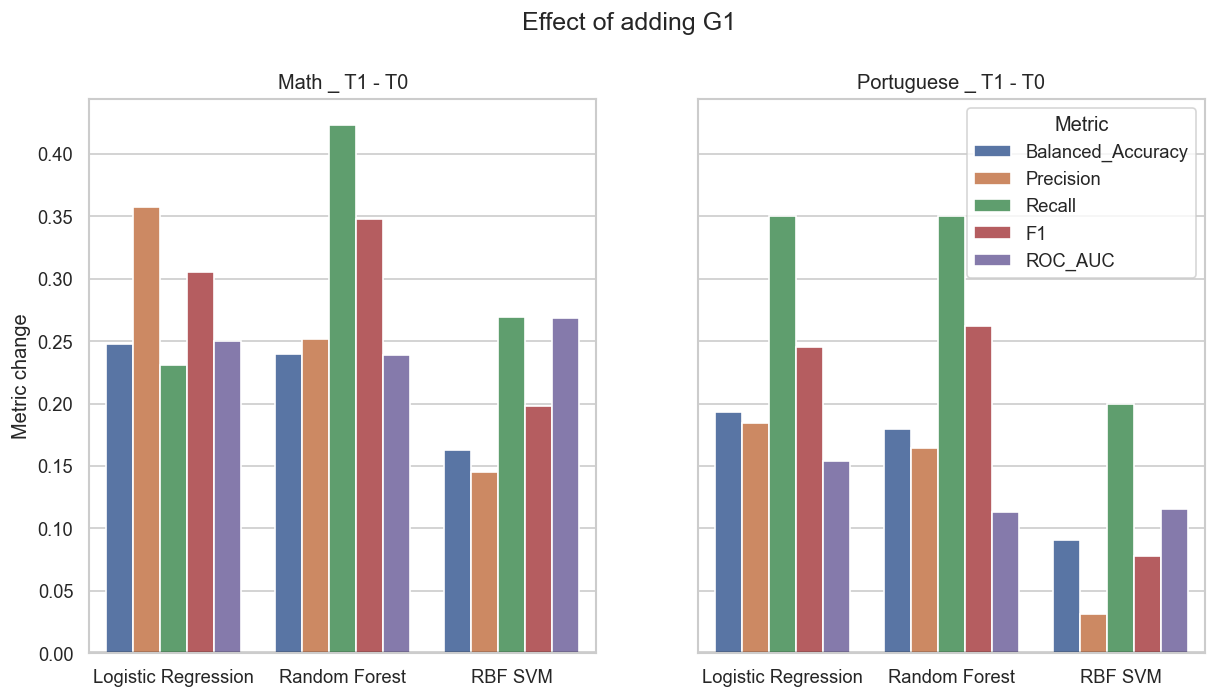

In [14]:
def selected_table(course, scenario):
    selected_model= best_by_scenario[
        (best_by_scenario["Course"] == course) & (best_by_scenario["Scenario"] == scenario)].iloc[0]["Model"]
    table = q1_predictions_df[
        (q1_predictions_df["Course"] == course) & (q1_predictions_df["Scenario"] == scenario) & (q1_predictions_df["Model"] == selected_model)
    ].sort_values("Student_position").reset_index(drop=True)
    return selected_model, table

def calculate_paired_delta(course,before, after, metrics):
    before_model,before_table = selected_table(course, before)
    after_model, after_table =selected_table(course, after)
    y_true = before_table["Actual_Risk"].to_numpy(dtype=int)
    before_pred = before_table["Predicted_Risk"].to_numpy(dtype=int)
    before_prob = before_table["Risk_probability"].to_numpy(dtype=float)
    after_pred= after_table["Predicted_Risk"].to_numpy(dtype=int)
    after_prob =after_table["Risk_probability"].to_numpy(dtype=float)
    before_point = calculate_all_metrics(y_true, before_pred, before_prob)
    after_point= calculate_all_metrics(y_true, after_pred,after_prob)

    rows = []
    for metric in metrics:
        rows.append({
            "Course": course,"Before": before,"After": after,
            "Before_model": before_model,"After_model": after_model,
            "Metric": metric,
            "Before_estimate": before_point[metric],"After_estimate": after_point[metric],"Delta": after_point[metric] - before_point[metric],
        })
    return rows
q4_paired_rows = []
for course in ["Math","Portuguese"]:
    q4_paired_rows.extend(calculate_paired_delta(
        course,before="T0",after="T1",
        metrics=["Accuracy","Balanced_Accuracy","Precision","Recall", "F1", "ROC_AUC","PR_AUC"]
    ))
q4_paired_delta = pd.DataFrame(q4_paired_rows)
print("Paired Delta (T1 - T0):")
print(q4_paired_delta.round(3).to_string(index=False))

q4_plot =q4_family_delta.melt(
    id_vars=["Course", "Model", "Comparison"],value_vars=["Balanced_Accuracy","Precision", "Recall", "F1", "ROC_AUC"],var_name="Metric",value_name="Delta",
)
fig,axes= plt.subplots(1,2,figsize=(12,6),sharey=True)
for ax,course in zip(axes, ["Math","Portuguese"]):
    sns.barplot(
        data=q4_plot[q4_plot["Course"] ==course],
        x="Model",y="Delta",
        hue="Metric",ax=ax,
    )
    ax.axhline(0, color="black",linewidth=2)
    ax.set_title(f"{course} _ T1 - T0")
    ax.set_xlabel("")
    ax.set_ylabel("Metric change")
    ax.tick_params(axis="x")
    if course== "Math":
        ax.get_legend().remove()
    else:
        ax.legend(bbox_to_anchor=(1.0001,1), title="Metric")
fig.suptitle("Effect of adding G1", y=1.001, fontsize=15)
plt.show()

<div  align="right">

## پرسش 5
</div>

In [15]:
q5_metrics = ["Accuracy", "Balanced_Accuracy","Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]
q5_model_delta = scenario_delta_table(q1_results_df, "T1","T2",q5_metrics)
q5_paired_rows = []
for course in ["Math", "Portuguese"]:
    q5_paired_rows.extend(calculate_paired_delta(
        course,before="T1",after="T2",
        metrics=["Accuracy","Balanced_Accuracy","Precision", "Recall","F1","ROC_AUC", "PR_AUC"]
    ))
q5_paired_delta =pd.DataFrame(q5_paired_rows)
print(q5_model_delta.round(3).to_string(index=False))
print("\n"+"\n")
print(q5_paired_delta.round(3).to_string(index=False))

    Course               Model Comparison  Accuracy  Balanced_Accuracy  Precision  Recall    F1  ROC_AUC  PR_AUC
      Math Logistic Regression    T2 - T1     0.076              0.096      0.082   0.154 0.115    0.045   0.076
      Math       Random Forest    T2 - T1     0.076              0.096      0.084   0.154 0.117    0.027   0.032
      Math             RBF SVM    T2 - T1     0.114              0.095      0.226   0.038 0.143    0.041   0.057
Portuguese Logistic Regression    T2 - T1     0.015              0.009      0.042   0.000 0.030    0.009   0.043
Portuguese       Random Forest    T2 - T1     0.023              0.095      0.013   0.200 0.089    0.023   0.088
Portuguese             RBF SVM    T2 - T1     0.077              0.045      0.179   0.000 0.136    0.012   0.035



    Course Before After        Before_model         After_model            Metric  Before_estimate  After_estimate  Delta
      Math     T1    T2 Logistic Regression Logistic Regression          Accuracy   

In [16]:
q5_grade_rows = []
q5_transition_rows = []
for course, frame in datasets.items():
    g2_risk = (frame["G2"] < 10).astype(int)
    final_risk = frame["Risk"].astype(int)
    q5_grade_rows.append({
        "Course": course,
        "Pearson G2 G3": frame["G2"].corr(frame["G3"]),
        "G2 agreement with final risk": (g2_risk == final_risk).mean(),
    })
    transition= pd.crosstab(g2_risk, final_risk, dropna=False).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
    for G2 in [0, 1]:
        row_total= transition.loc[G2].sum()
        for final_state in [0,1]:
            q5_transition_rows.append({
                "Course":course,"G2 < 10": G2,
                "Final Risk": final_state,"Count": int(transition.loc[G2, final_state]),
                "Rate within G2": transition.loc[G2, final_state] /row_total,
            })
q5_grade_relationship = pd.DataFrame(q5_grade_rows)
q5_transitions =pd.DataFrame(q5_transition_rows)
print(q5_grade_relationship.round(3).to_string(index=False))
print("\n"+"\n")
print(q5_transitions.round(3).to_string(index=False))

    Course  Pearson G2 G3  G2 agreement with final risk
      Math          0.905                         0.919
Portuguese          0.919                         0.897



    Course  G2 < 10  Final Risk  Count  Rate within G2
      Math        0           0    241           0.968
      Math        0           1      8           0.032
      Math        1           0     24           0.164
      Math        1           1    122           0.836
Portuguese        0           0    493           0.978
Portuguese        0           1     11           0.022
Portuguese        1           0     56           0.386
Portuguese        1           1     89           0.614


    Course                 Method               Model  Accuracy  Balanced_Accuracy  Precision  Recall    F1  ROC_AUC  PR_AUC  False_Negative_Rate  FN  TP
      Math Selected full model T1 Logistic Regression     0.886              0.876      0.815   0.846 0.830    0.948   0.908                0.154   4  22
      Math Selected full model T2 Logistic Regression     0.962              0.972      0.897   1.000 0.945    0.993   0.984                0.000   0  26
      Math       G2-only logistic Logistic Regression     0.949              0.962      0.867   1.000 0.929    0.991   0.969                0.000   0  26
      Math          Rule: G2 < 10    Single threshold     0.949              0.962      0.867   1.000 0.929    0.991   0.969                0.000   0  26
Portuguese Selected full model T1       Random Forest     0.923              0.873      0.727   0.800 0.762    0.970   0.877                0.200   4  16
Portuguese Selected full model T2       Random Forest     0.946             

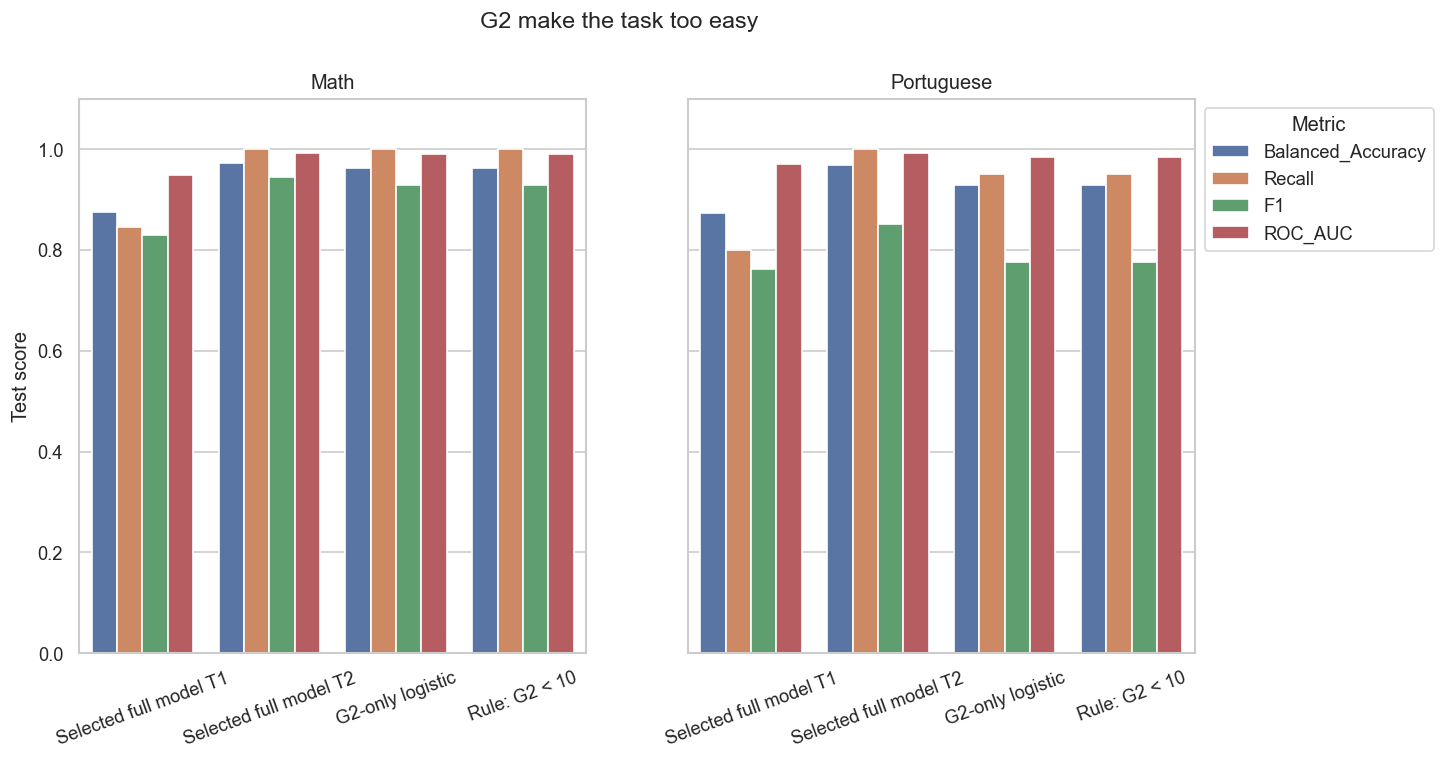

In [17]:
q5_comparison_rows= []
for course,frame in datasets.items():
    train_pos,validation_pos, test_pos= flexible_split(frame["Risk"])
    train_validation_pos = np.concatenate([train_pos, validation_pos])
    y_test =frame.iloc[test_pos]["Risk"].to_numpy(dtype=int)
    for scenario in ["T1","T2"]:
        model_name, prediction_table =selected_table(course,scenario)
        row= {"Course": course,"Method": f"Selected full model {scenario}","Model": model_name,}
        row.update(calculate_all_metrics(
            prediction_table["Actual_Risk"],
            prediction_table["Predicted_Risk"],
            prediction_table["Risk_probability"],
        ))
        q5_comparison_rows.append(row)
    G2_model =Pipeline([("scale",StandardScaler()),("model", LogisticRegression(C=1,class_weight="balanced",max_iter=4000,solver="liblinear",random_state=RANDOM_STATE,)),])
    G2_model.fit(frame.iloc[train_validation_pos][["G2"]], frame.iloc[train_validation_pos]["Risk"])
    G2_prob =G2_model.predict_proba(frame.iloc[test_pos][["G2"]])[:, 1]
    G2_pred= G2_model.predict(frame.iloc[test_pos][["G2"]])
    row= {"Course": course, "Method": "G2-only logistic","Model": "Logistic Regression"}
    row.update(calculate_all_metrics(y_test, G2_pred,G2_prob))
    q5_comparison_rows.append(row)
    G2_rule_pred = (frame.iloc[test_pos]["G2"].to_numpy() < 10).astype(int)
    G2_rule_prob = (20.0 - frame.iloc[test_pos]["G2"].to_numpy(dtype=float)) / 20.0
    row= {"Course": course, "Method": "Rule: G2 < 10", "Model": "Single threshold"}
    row.update(calculate_all_metrics(y_test, G2_rule_pred, G2_rule_prob))
    q5_comparison_rows.append(row)
q5_simplecomparison = pd.DataFrame(q5_comparison_rows)
print(q5_simplecomparison[
    [
        "Course", "Method", "Model", "Accuracy", "Balanced_Accuracy", "Precision",
        "Recall", "F1", "ROC_AUC", "PR_AUC","False_Negative_Rate", "FN", "TP",
    ]].round(3).to_string(index=False))
q5_plot =q5_simplecomparison.melt(
    id_vars=["Course", "Method", "Model"],value_vars=["Balanced_Accuracy", "Recall", "F1", "ROC_AUC"],
    var_name="Metric",value_name="Score",
)
fig,axes = plt.subplots(1, 2, figsize=(12,6),sharey=True)
for ax, course in zip(axes, ["Math","Portuguese"]):
    sns.barplot(data=q5_plot[q5_plot["Course"] == course],x="Method",y="Score",hue="Metric",ax=ax,)
    ax.set_ylim(0,1.1)
    ax.set_title(course)
    ax.set_xlabel("")
    ax.set_ylabel("Test score")
    ax.tick_params(axis="x",rotation = 20)
    if course == "Math":
        ax.get_legend().remove()
    else:
        ax.legend(bbox_to_anchor=(1.001, 1), title="Metric")
fig.suptitle("G2 make the task too easy", y=1.001, fontsize=14)
plt.show()

<div  align="right">

## پرسش 6
</div>

In [18]:
def estimator_from_selected_configuration(model_name, selected_parameters):
    parameters = json.loads(selected_parameters)
    for family, candidate_parameters, estimator in candidate_models():
        if family== model_name and candidate_parameters== parameters:
            return estimator
q6_distribution_rows = []
q6_threshold12_rows = []
q6_prediction_rows = []
for course,frame in datasets.items():
    risk_10 =(frame["G3"] < 10).astype(int)
    risk_12= (frame["G3"] <12).astype(int)
    train_pos,validation_pos, test_pos = course_splits[course]
    q6_distribution_rows.extend([
        {
            "Course": course,"Threshold": 10,
            "At_risk": int(risk_10.sum()),"Not_at_risk": int((risk_10 == 0).sum()),"Risk_rate": float(risk_10.mean()),
        },
        {
            "Course": course,"Threshold":12,
            "At_risk": int(risk_12.sum()),"Not_at_risk": int((risk_12 == 0).sum()),"Risk_rate": float(risk_12.mean()),
        },
    ])
    for scenario in SCENARIOS:
        selected_q1 =best_by_scenario[(best_by_scenario["Course"] == course) & (best_by_scenario["Scenario"] == scenario)].iloc[0]
        model_name = selected_q1["Model"]
        selected_parameters = selected_q1["Selected_parameters"]
        X, _ =scenario_xy(frame, scenario)
        y= risk_12
        X_train, y_train= X.iloc[train_pos], y.iloc[train_pos]
        X_validation,y_validation = X.iloc[validation_pos], y.iloc[validation_pos]
        X_test,y_test =X.iloc[test_pos], y.iloc[test_pos]
        estimator = estimator_from_selected_configuration(model_name,selected_parameters,)
        validation_model= Pipeline([("preprocess", preprocessor(X_train)),("model", estimator),])
        validation_model.fit(X_train, y_train)
        validation_prediction= validation_model.predict(X_validation)
        validation_probability = probability_of_risk(validation_model,X_validation,)
        validation_metrics = calculate_all_metrics(y_validation,validation_prediction,validation_probability,)
        X_train_validation = pd.concat([X_train, X_validation], axis=0)
        y_train_validation = pd.concat([y_train, y_validation], axis=0)
        final_model= clone(validation_model)
        final_model.fit(X_train_validation, y_train_validation)
        test_prediction = final_model.predict(X_test)
        test_probability =probability_of_risk(final_model, X_test)
        test_metrics= calculate_all_metrics(y_test,test_prediction,test_probability,)
        row = {
            "Task": "Risk_Threshold_12","Course": course,"Scenario": scenario,
            "Threshold": 12,"Model": model_name,"Selected_parameters": selected_parameters,
        }
        for metric_name,metric_value in validation_metrics.items():
            row[f"Validation_{metric_name}"]= metric_value
        row.update(test_metrics)
        q6_threshold12_rows.append(row)
        for position, actual,predicted,probability in zip(test_pos,y_test,test_prediction,test_probability,):
            q6_prediction_rows.append({
                "Course": course,"Scenario": scenario,"Model": model_name,"Student_position": int(position),
                "Actual_Risk": int(actual),"Predicted_Risk": int(predicted),"Risk_probability": float(probability),
            })
q6_distribution = pd.DataFrame(q6_distribution_rows)
q6_threshold12_selected= pd.DataFrame(q6_threshold12_rows)
q6_predictions_threshold12 =pd.DataFrame(q6_prediction_rows)
q6_threshold10_selected= best_by_scenario.copy()
q6_threshold10_selected["Threshold"]=10
comparison_columns = [
    "Course","Scenario","Threshold","Model",
    "Validation_F1","Validation_Balanced_Accuracy",
    "Accuracy","Balanced_Accuracy","Precision","Recall",
    "Specificity","F1","ROC_AUC","PR_AUC","FN","TP",
]
q6_selected_comparison= pd.concat([
    q6_threshold10_selected[comparison_columns],
    q6_threshold12_selected[comparison_columns],
], ignore_index=True).sort_values(["Course","Scenario","Threshold"]).reset_index(drop=True)
q6_metrics_for_delta = ["Accuracy","Balanced_Accuracy","Precision","Recall","F1","ROC_AUC","PR_AUC",]
threshold_10_table = q6_selected_comparison[q6_selected_comparison["Threshold"] == 10].set_index(["Course", "Scenario"])
threshold_12_table= q6_selected_comparison[q6_selected_comparison["Threshold"] == 12].set_index(["Course", "Scenario"])

print("Class distribution after changing the risk threshold:")
print(q6_distribution.to_string(index=False,formatters={"Risk_rate": "{:.3f}".format},))
print("\nSame validation-selected model _ thresholds 10 and 12:")
print(q6_selected_comparison[[
    "Course","Scenario","Threshold","Model","Validation_F1",
    "Accuracy","Balanced_Accuracy","Precision",
    "Recall","F1","PR_AUC","FN","TP",
]].round(3).to_string(index=False))

Class distribution after changing the risk threshold:
    Course  Threshold  At_risk  Not_at_risk Risk_rate
      Math         10      130          265     0.329
      Math         12      233          162     0.590
Portuguese         10      100          549     0.154
Portuguese         12      301          348     0.464

Same validation-selected model _ thresholds 10 and 12:
    Course Scenario  Threshold               Model  Validation_F1  Accuracy  Balanced_Accuracy  Precision  Recall    F1  PR_AUC  FN  TP
      Math       T0         10 Logistic Regression          0.588     0.633              0.628      0.457   0.615 0.525   0.618  10  16
      Math       T0         12 Logistic Regression          0.723     0.582              0.590      0.676   0.543 0.602   0.748  21  25
      Math       T1         10 Logistic Regression          0.727     0.886              0.876      0.815   0.846 0.830   0.908   4  22
      Math       T1         12 Logistic Regression          0.865     0.785 

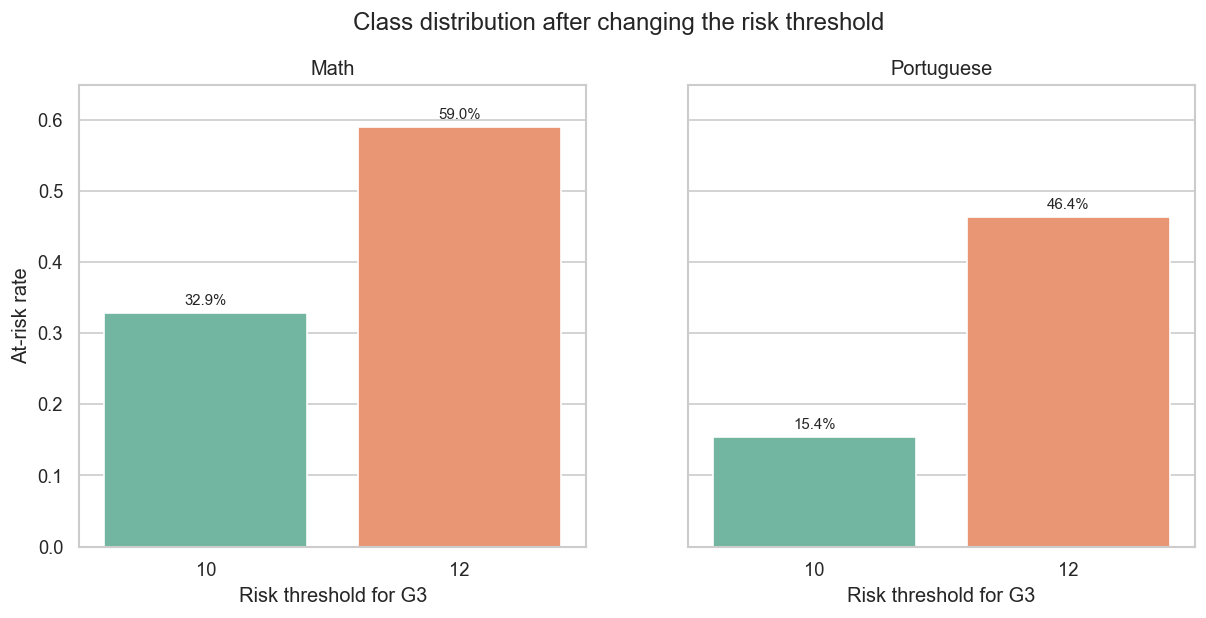

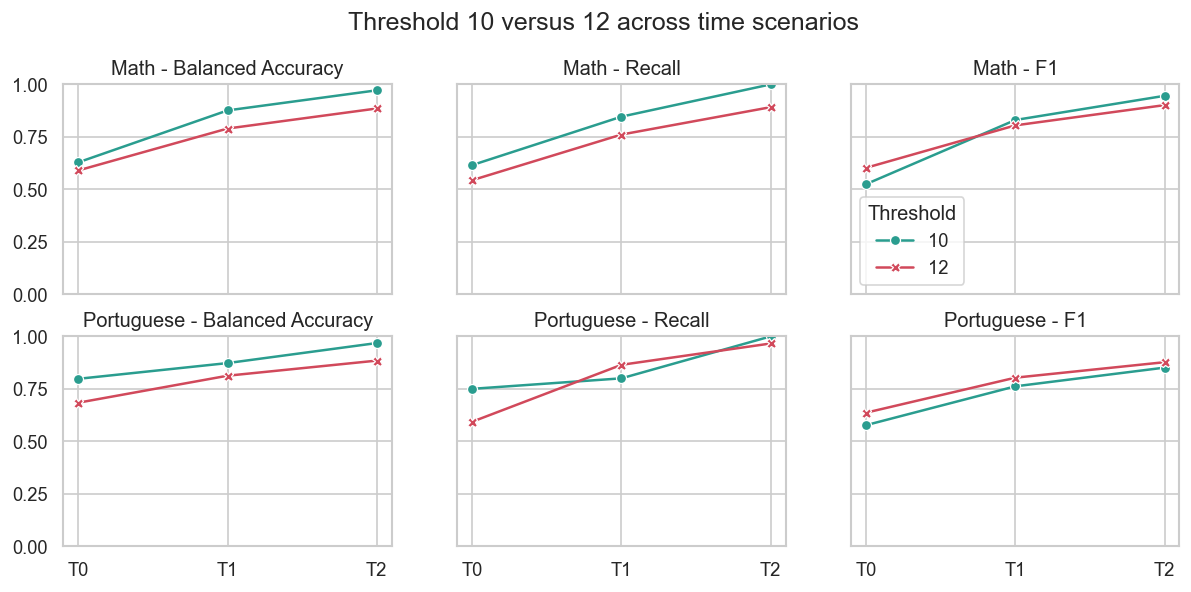

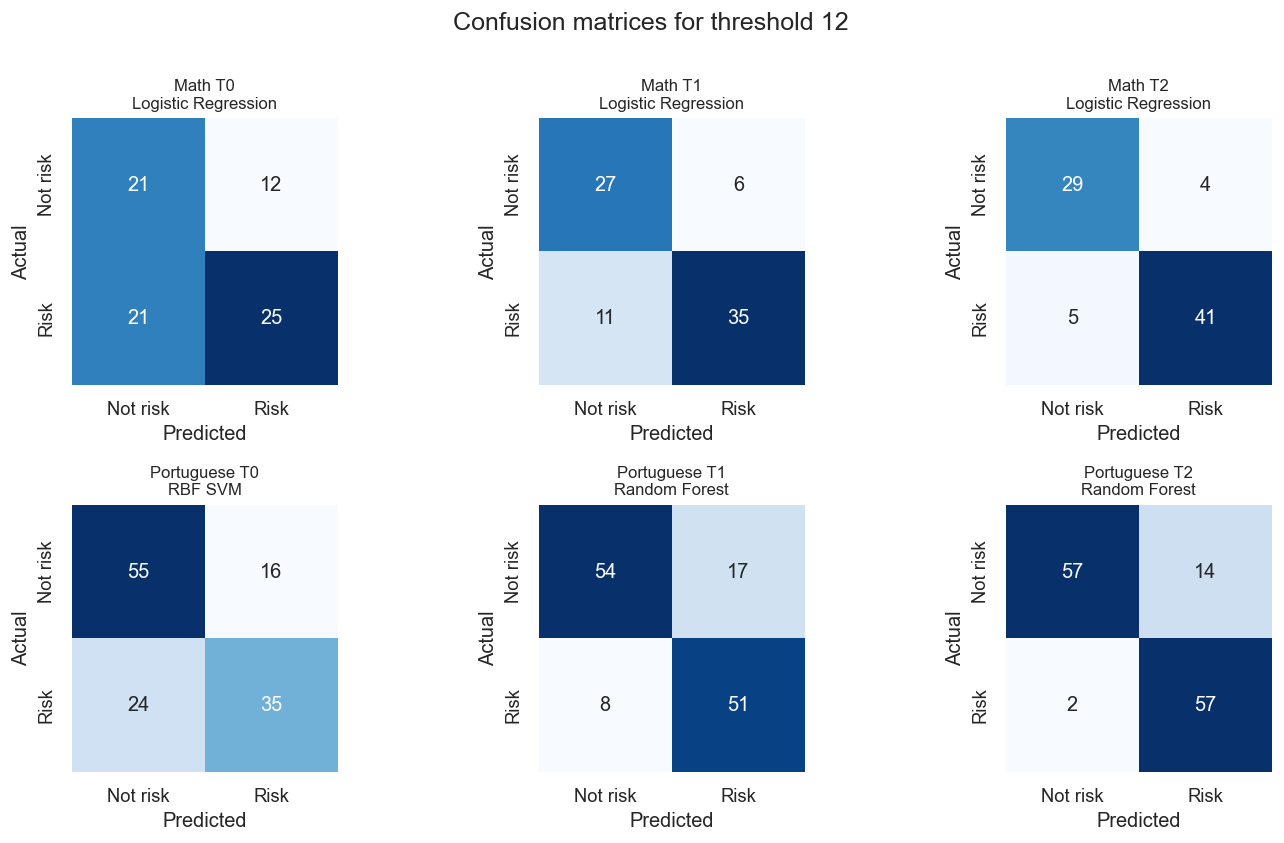

In [19]:
fig,axes = plt.subplots(1, 2,figsize=(12,5), sharey=True)
for ax,course in zip(axes,["Math","Portuguese"]):
    chart_data= q6_distribution[q6_distribution["Course"] ==course]
    sns.barplot(
        data=chart_data,x="Threshold",y="Risk_rate",
        hue="Threshold",palette="Set2",legend=False,ax=ax,
    )
    for p,value in zip(ax.patches,chart_data["Risk_rate"]):
        ax.annotate(
            f"{value:.1%}",(p.get_x()+ p.get_width() /2,p.get_height()),
            ha="center",va="bottom",xytext=(0,3),
            textcoords="offset points",fontsize=9,
        )
    ax.set_ylim(0, max(0.65,chart_data["Risk_rate"].max()+ 0.1))
    ax.set_title(course)
    ax.set_xlabel("Risk threshold for G3")
    ax.set_ylabel("At-risk rate" if course== "Math" else "")
fig.suptitle("Class distribution after changing the risk threshold",y=1.001,)
plt.show()

metrics_to_plot = ["Balanced_Accuracy","Recall", "F1"]
fig, axes = plt.subplots(2,3, figsize=(12,5), sharex=True, sharey=True)
for row_index,course in enumerate(["Math", "Portuguese"]):
    for column_index,metric in enumerate(metrics_to_plot):
        ax= axes[row_index, column_index]
        chart_data= q6_selected_comparison[q6_selected_comparison["Course"] == course].copy()
        chart_data["Scenario"] = pd.Categorical(
            chart_data["Scenario"],
            categories=["T0","T1","T2"],
            ordered=True,
        )
        chart_data =chart_data.sort_values(["Threshold","Scenario"])
        sns.lineplot(
            data=chart_data,x="Scenario",y=metric,
            hue="Threshold",style="Threshold",markers=True,
            dashes=False,palette={10: "#2A9D8F", 12: "#D1495B"},ax=ax,
        )
        ax.set_ylim(0,1.001)
        ax.set_title(f"{course} - {metric.replace('_',' ')}")
        ax.set_xlabel("")
        ax.set_ylabel("")
        if not (row_index== 0 and column_index ==2):
            legend= ax.get_legend()
            if legend is not None:
                legend.remove()
fig.suptitle("Threshold 10 versus 12 across time scenarios",y=1.001,fontsize=15,)
plt.show()

fig,axes =plt.subplots(2, 3,figsize=(12,7))
q6_selected_prediction = {}
for row_index,course in enumerate(["Math", "Portuguese"]):
    for column_index, scenario in enumerate(["T0","T1", "T2"]):
        selected_model= q6_threshold12_selected[
            (q6_threshold12_selected["Course"]== course)& (q6_threshold12_selected["Scenario"] ==scenario)
        ].iloc[0]["Model"]
        prediction_table= q6_predictions_threshold12[
            (q6_predictions_threshold12["Course"]== course)& (q6_predictions_threshold12["Scenario"] == scenario)& (q6_predictions_threshold12["Model"]== selected_model)
        ].sort_values("Student_position")
        q6_selected_prediction[(course, scenario)] = prediction_table
        matrix = confusion_matrix(prediction_table["Actual_Risk"],prediction_table["Predicted_Risk"],labels=[0,1],)
        sns.heatmap(
            matrix,
            annot=True,fmt="d",cmap="Blues",cbar=False,square=True,
            xticklabels=["Not risk","Risk"],yticklabels=["Not risk", "Risk"],ax=axes[row_index, column_index],
        )
        axes[row_index,column_index].set_title(f"{course} {scenario}\n{selected_model}",fontsize=10,)
        axes[row_index, column_index].set_xlabel("Predicted")
        axes[row_index,column_index].set_ylabel("Actual")
fig.suptitle("Confusion matrices for threshold 12",y=1.001,fontsize=15,)
plt.tight_layout()
plt.show()

<div  align="right">

## پرسش 7
</div>

In [20]:
RISK_LEVELS = ["High risk","Medium risk", "Low risk"]
def Three_level_target(frame):
    return pd.Series(
        np.select([frame["G3"] <10, frame["G3"] <13],["High risk", "Medium risk"],
            default="Low risk",
        ),
        index=frame.index,name="Risk_level",
    )
def Multiclass_metrics(y_true, y_predict):
    return {
        "Accuracy": accuracy_score(y_true, y_predict),"Balanced_Accuracy": balanced_accuracy_score(y_true, y_predict),
        "Macro_Precision": precision_score(y_true, y_predict, average="macro", zero_division=0),
        "Macro_Recall": recall_score(y_true, y_predict, average="macro", zero_division=0),
        "Macro_F1":f1_score(y_true, y_predict, average="macro", zero_division=0),
    }
def multiclass_validation_rank(metrics):
    return (float(metrics["Macro_F1"]),float(metrics["Balanced_Accuracy"]),float(metrics["Accuracy"]),)

def multiclass_candidate_models():
    candidates= []
    for C in [0.1,1,10]:
        candidates.append((
            "Logistic Regression",
            {"C": C},
            LogisticRegression(
                C=C,class_weight="balanced",max_iter=4000,
                solver="lbfgs",random_state=RANDOM_STATE,
            ),
        ))
    for max_depth, min_leaf in product([None,10], [1,4]):
        candidates.append((
            "Random Forest",
            {"max_depth": max_depth, "min_samples_leaf": min_leaf},
            RandomForestClassifier(
                n_estimators=250,max_depth=max_depth,min_samples_leaf=min_leaf,
                class_weight="balanced_subsample",random_state=RANDOM_STATE,n_jobs=1,
            ),
        ))
    for C,gamma in product([0.5,2], ["scale","auto"]):
        candidates.append((
            "RBF SVM",
            {"C":C,"gamma": gamma},
            SVC(
                C=C,gamma=gamma,kernel="rbf",
                class_weight="balanced",probability=False,random_state=RANDOM_STATE,
            ),
        ))
    return candidates

def train_and_evaluate_multiclass(frame,target, course,splits):
    train_pos,validation_pos, test_pos = splits
    result_rows = []
    prediction_rows=[]
    for scenario in SCENARIOS:
        X, _ = scenario_xy(frame, scenario)
        y =pd.Series(np.asarray(target),index=frame.index,name="Risk_level")
        X_train, y_train = X.iloc[train_pos], y.iloc[train_pos]
        X_validation,y_validation = X.iloc[validation_pos],y.iloc[validation_pos]
        X_test, y_test= X.iloc[test_pos], y.iloc[test_pos]
        best_hyperparameter_by_family = {}

        for family,parameters,estimator in multiclass_candidate_models():
            pipeline = Pipeline([("preprocess", preprocessor(X_train)),("model", estimator),])
            pipeline.fit(X_train, y_train)
            validation_prediction = pipeline.predict(X_validation)
            validation_metrics =Multiclass_metrics( y_validation, validation_prediction)
            rank= multiclass_validation_rank(validation_metrics)
            if (family not in best_hyperparameter_by_family or rank > best_hyperparameter_by_family[family]["rank"]):
                best_hyperparameter_by_family[family] = {
                    "rank":rank,"pipeline": pipeline,
                    "parameters": parameters,"validation_metrics":validation_metrics,
                }

        X_train_validation = pd.concat([X_train,X_validation], axis=0)
        y_train_validation= pd.concat([y_train, y_validation],axis=0)
        for family, selected in best_hyperparameter_by_family.items():
            final_model= clone(selected["pipeline"])
            final_model.fit(X_train_validation,y_train_validation)
            test_prediction = final_model.predict(X_test)
            test_metrics= Multiclass_metrics(y_test, test_prediction)
            row = {
                "Task": "Three_Level_Risk","Course": course,
                "Scenario": scenario,"Model": family,
                "Selected_parameters": json.dumps(selected["parameters"], sort_keys=True),
            }
            for metric_name, metric_value in selected["validation_metrics"].items():
                row[f"Validation_{metric_name}"] =metric_value
            row.update(test_metrics)
            result_rows.append(row)

            for position, actual, predicted in zip(test_pos, y_test, test_prediction):
                prediction_rows.append({
                    "Course": course,"Scenario": scenario,"Model": family,
                    "Student_position": int(position),"Actual_Risk_level": actual,"Predicted_Risk_level": predicted,
                })
    return pd.DataFrame(result_rows), pd.DataFrame(prediction_rows)

def select_multiclass_by_validation(result_table):
    ranking_columns = [
        "Course","Scenario",
        "Validation_Macro_F1","Validation_Balanced_Accuracy","Validation_Accuracy",
    ]
    return (
        result_table.sort_values(
            ranking_columns,
            ascending=[True, True, False, False, False],na_position="last",
        ).groupby(["Course", "Scenario"], as_index=False).first()
    )
q7_distribution_rows = []
q7_result = []
q7_prediction_f = []
q7_splits = {}
for course, frame in datasets.items():
    target_q7= Three_level_target(frame)
    q7_splits[course] = flexible_split(target_q7,seed=RANDOM_STATE,)
    counts =target_q7.value_counts().reindex(RISK_LEVELS, fill_value=0)
    for risk_level in RISK_LEVELS:
        q7_distribution_rows.append({
            "Course": course,"Risk_level": risk_level,
            "Count": int(counts[risk_level]),"Rate": float(counts[risk_level] / len(frame)),
        })
    result_table,prediction_table = train_and_evaluate_multiclass(
        frame=frame,target=target_q7,course=course,splits=q7_splits[course],)
    q7_result.append(result_table)
    q7_prediction_f.append(prediction_table)
q7_distribution= pd.DataFrame(q7_distribution_rows)
q7_all_results =pd.concat(q7_result,ignore_index=True)
q7_predictions = pd.concat(q7_prediction_f, ignore_index=True)
q7_selected= select_multiclass_by_validation(q7_all_results)
q7_selected_prediction_rows= []
q7_per_class_rows = []
q7_confusion_rows = []
q7_selected_prediction_tables ={}
for course in datasets:
    for scenario in SCENARIOS:
        selected_model = q7_selected[(q7_selected["Course"] == course)& (q7_selected["Scenario"] == scenario)].iloc[0]["Model"]
        selected_predictions = q7_predictions[
            (q7_predictions["Course"] == course)& (q7_predictions["Scenario"] == scenario)& (q7_predictions["Model"] == selected_model)].sort_values("Student_position")
        q7_selected_prediction_tables[(course, scenario)] = selected_predictions
        q7_selected_prediction_rows.append(selected_predictions)
        precision_values, recall_values,f1_values, support_values= (
            precision_recall_fscore_support(
                selected_predictions["Actual_Risk_level"],selected_predictions["Predicted_Risk_level"],
                labels=RISK_LEVELS,
                zero_division=0,
            )
        )
        for risk_level,precision_value, recall_value, f1_value,support_value in zip(RISK_LEVELS,precision_values,recall_values,f1_values,support_values,):
            q7_per_class_rows.append({
                "Course": course,"Scenario": scenario,"Model": selected_model,
                "Risk_level": risk_level,"Precision": precision_value,"Recall": recall_value,
                "F1": f1_value,"Support": int(support_value),
            })
        matrix = confusion_matrix(
            selected_predictions["Actual_Risk_level"],
            selected_predictions["Predicted_Risk_level"],
            labels=RISK_LEVELS,
        )
        for actual_index,actual_level in enumerate(RISK_LEVELS):
            for predicted_index,predicted_level in enumerate(RISK_LEVELS):
                q7_confusion_rows.append({
                    "Course": course,"Scenario": scenario,"Model": selected_model,
                    "Actual_Risk_level": actual_level,"Predicted_Risk_level": predicted_level,"Count": int(matrix[actual_index,predicted_index]),
                })

q7_selected_predictions = pd.concat(q7_selected_prediction_rows,ignore_index=True,)
q7_per_class= pd.DataFrame(q7_per_class_rows)
q7_confusion_long =pd.DataFrame(q7_confusion_rows)

print("Three level class distribution:")
print(q7_distribution.to_string(index=False,formatters={"Rate":"{:.3f}".format},))
print("\nValidation selected models:")
print(q7_selected[["Course","Scenario","Model","Accuracy","Balanced_Accuracy","Macro_Precision","Macro_Recall","Macro_F1",]].round(3).to_string(index=False))

Three level class distribution:
    Course  Risk_level  Count  Rate
      Math   High risk    130 0.329
      Math Medium risk    134 0.339
      Math    Low risk    131 0.332
Portuguese   High risk    100 0.154
Portuguese Medium risk    273 0.421
Portuguese    Low risk    276 0.425

Validation selected models:
    Course Scenario               Model  Accuracy  Balanced_Accuracy  Macro_Precision  Macro_Recall  Macro_F1
      Math       T0             RBF SVM     0.342              0.341            0.349         0.341     0.342
      Math       T1 Logistic Regression     0.658              0.659            0.673         0.659     0.664
      Math       T2       Random Forest     0.861              0.862            0.863         0.862     0.862
Portuguese       T0       Random Forest     0.500              0.477            0.471         0.477     0.472
Portuguese       T1       Random Forest     0.746              0.724            0.705         0.724     0.713
Portuguese       T2       R

In [21]:
print("\nPer class test metrics of selected models:")
print(q7_per_class.round(3).to_string(index=False))


Per class test metrics of selected models:
    Course Scenario               Model  Risk_level  Precision  Recall    F1  Support
      Math       T0             RBF SVM   High risk      0.333   0.346 0.340       26
      Math       T0             RBF SVM Medium risk      0.312   0.370 0.339       27
      Math       T0             RBF SVM    Low risk      0.400   0.308 0.348       26
      Math       T1 Logistic Regression   High risk      0.773   0.654 0.708       26
      Math       T1 Logistic Regression Medium risk      0.516   0.593 0.552       27
      Math       T1 Logistic Regression    Low risk      0.731   0.731 0.731       26
      Math       T2       Random Forest   High risk      0.821   0.885 0.852       26
      Math       T2       Random Forest Medium risk      0.808   0.778 0.792       27
      Math       T2       Random Forest    Low risk      0.960   0.923 0.941       26
Portuguese       T0       Random Forest   High risk      0.421   0.400 0.410       20
Portuguese

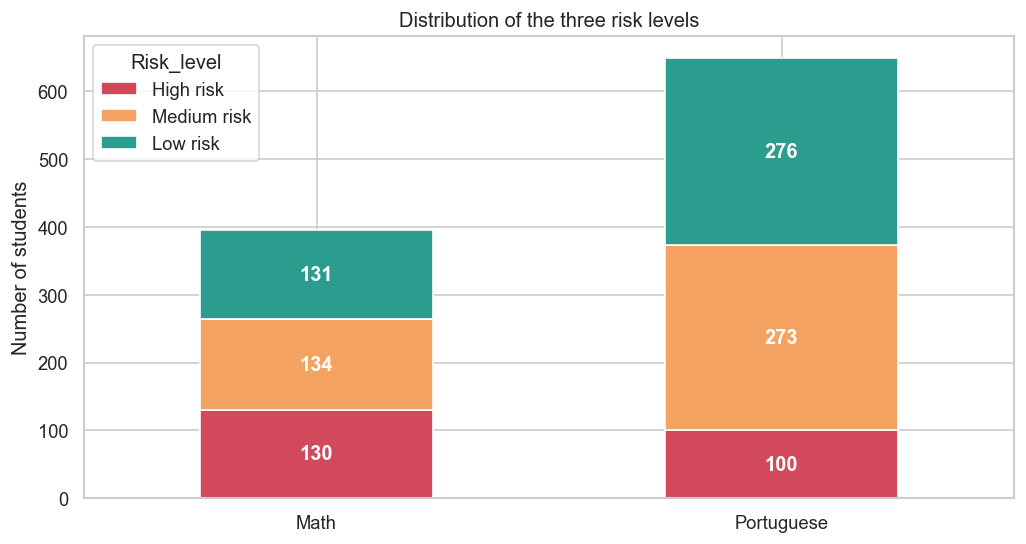

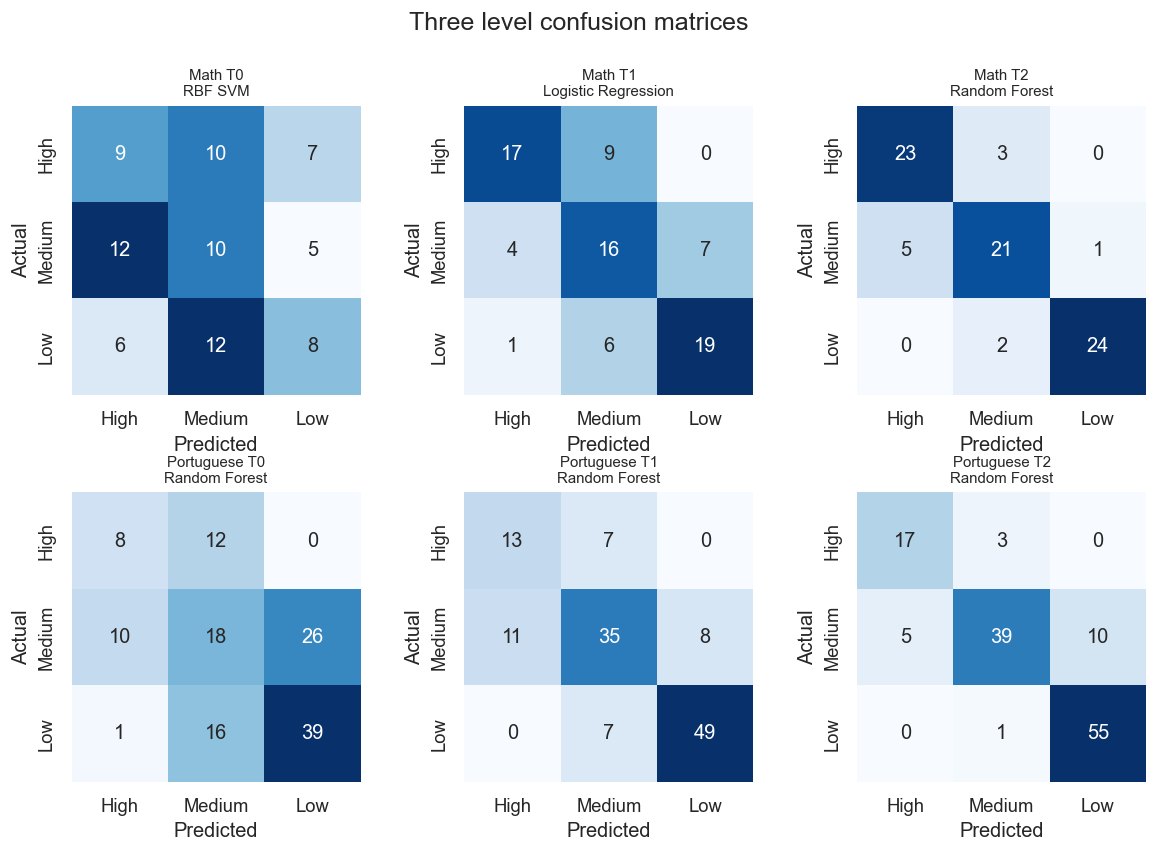

In [22]:
q7_distribution_plot = q7_distribution.copy()
q7_distribution_plot["Risk_level"] = pd.Categorical(q7_distribution_plot["Risk_level"],categories=RISK_LEVELS,ordered=True,)
q7_distribution_pivot = (q7_distribution_plot.pivot(index="Course",columns="Risk_level",values="Count",).reindex(columns=RISK_LEVELS))
ax =q7_distribution_pivot.plot(
    kind="bar",stacked=True,
    figsize=(10,5),
    color=["#D1495B", "#F4A261", "#2A9D8F"],
)
for c in ax.containers:
    ax.bar_label(
        c,label_type="center",fontsize=12,
        color="white",fontweight="bold",
    )
ax.set_title("Distribution of the three risk levels")
ax.set_xlabel("")
ax.set_ylabel("Number of students",)
ax.tick_params(axis="x",rotation=0)
plt.show()

fig,axes = plt.subplots(2, 3,figsize=(10,7))
for row_index,course in enumerate(["Math", "Portuguese"]):
    for column_index, scenario in enumerate(["T0","T1","T2"]):
        selected_predictions= q7_selected_prediction_tables[(course, scenario)]
        model_name =selected_predictions["Model"].iloc[0]
        matrix = confusion_matrix(selected_predictions["Actual_Risk_level"],selected_predictions["Predicted_Risk_level"],labels=RISK_LEVELS,)
        sns.heatmap(
            matrix,annot=True,fmt="d",cmap="Blues",cbar=False,square=True,
            xticklabels=["High", "Medium", "Low"],yticklabels=["High","Medium", "Low"],ax=axes[row_index, column_index],
        )
        axes[row_index,column_index].set_title(f"{course} {scenario}\n{model_name}",fontsize=9,)
        axes[row_index, column_index].set_xlabel("Predicted")
        axes[row_index, column_index].set_ylabel("Actual")
fig.suptitle("Three level confusion matrices",y=1.001,fontsize=15,)
plt.tight_layout()
plt.show()

<div  align="right">

## پرسش 8
</div>

In [23]:
q8_distribution_rows = []
q8_result = []
q8_prediction_f = []
q8_splits = {}
for course,frame in datasets.items():
    target_q8= (frame["G3"]>=16).astype(int)
    q8_splits[course]= flexible_split(target_q8,seed=RANDOM_STATE+8,)
    q8_distribution_rows.append({
        "Course": course,"Excellent": int(target_q8.sum()),
        "Not_excellent":int((target_q8== 0).sum()),"Excellent_rate": float(target_q8.mean()),"Threshold": 16,
    })
    result_table, _,prediction_table = train_and_evaluate_task(
        frame=frame,target=target_q8,task_name="Excellent_G3_at_least_16",
        course=course,splits=q8_splits[course],
    )
    q8_result.append(result_table)
    q8_prediction_f.append(prediction_table)
q8_distribution =pd.DataFrame(q8_distribution_rows)
q8_all_results= pd.concat(q8_result, ignore_index=True)
q8_predictions= pd.concat(q8_prediction_f, ignore_index=True).rename(columns={
    "Actual_Risk":"Actual_Excellent",
    "Predicted_Risk":"Predicted_Excellent",
    "Risk_probability":"Excellent_probability",
})
q8_selected=select_by_validation(q8_all_results)
q8_prediction_rows = []
q8_prediction_tables ={}
q8_confusion_rows =[]

for course,frame in datasets.items():
        for scenario in SCENARIOS :
             selected_model =q8_selected[(q8_selected["Course"] == course)& (q8_selected["Scenario"] == scenario)].iloc[0]["Model"]
             selected_predictions= q8_predictions[
                  (q8_predictions["Course"] ==course)& (q8_predictions["Scenario"] == scenario)& (q8_predictions["Model"]== selected_model)
                  ].sort_values("Student_position")
             q8_prediction_tables[(course,scenario)] = selected_predictions
             q8_prediction_rows.append(selected_predictions)
             matrix= confusion_matrix(
                  selected_predictions["Actual_Excellent"],selected_predictions["Predicted_Excellent"],labels=[0,1],
                  )
             for actual_class in [0,1]:
                for predicted_class in [0,1]:
                     q8_confusion_rows.append({
                          "Course": course,"Scenario": scenario,"Model": selected_model,
                          "Actual_Excellent": actual_class,"Predicted_Excellent": predicted_class,
                          "Count": int(matrix[actual_class, predicted_class]),
                          })
q8_selected_predictions = pd.concat(q8_prediction_rows,ignore_index=True,)
q8_confusion_long =pd.DataFrame(q8_confusion_rows)

print("Excellent student class distribution:")
print(q8_distribution.to_string(index=False,formatters={"Excellent_rate": "{:.3f}".format},))
print("\nValidation selected models:")
print(q8_selected[[
    "Course","Scenario","Model","Validation_F1","Validation_Balanced_Accuracy",
    "Accuracy","Balanced_Accuracy","Precision","Recall","F1","ROC_AUC","PR_AUC","FN","TP",
]].round(3).to_string(index=False))

Excellent student class distribution:
    Course  Excellent  Not_excellent Excellent_rate  Threshold
      Math         40            355          0.101         16
Portuguese         82            567          0.126         16

Validation selected models:
    Course Scenario               Model  Validation_F1  Validation_Balanced_Accuracy  Accuracy  Balanced_Accuracy  Precision  Recall    F1  ROC_AUC  PR_AUC  FN  TP
      Math       T0             RBF SVM          0.273                         0.610     0.785              0.603      0.200   0.375 0.261    0.732   0.367   5   3
      Math       T1 Logistic Regression          0.941                         0.993     0.924              0.902      0.583   0.875 0.700    0.958   0.800   1   7
      Math       T2 Logistic Regression          0.941                         0.993     0.937              0.909      0.636   0.875 0.737    0.975   0.842   1   7
Portuguese       T0             RBF SVM          0.264                         0.578    

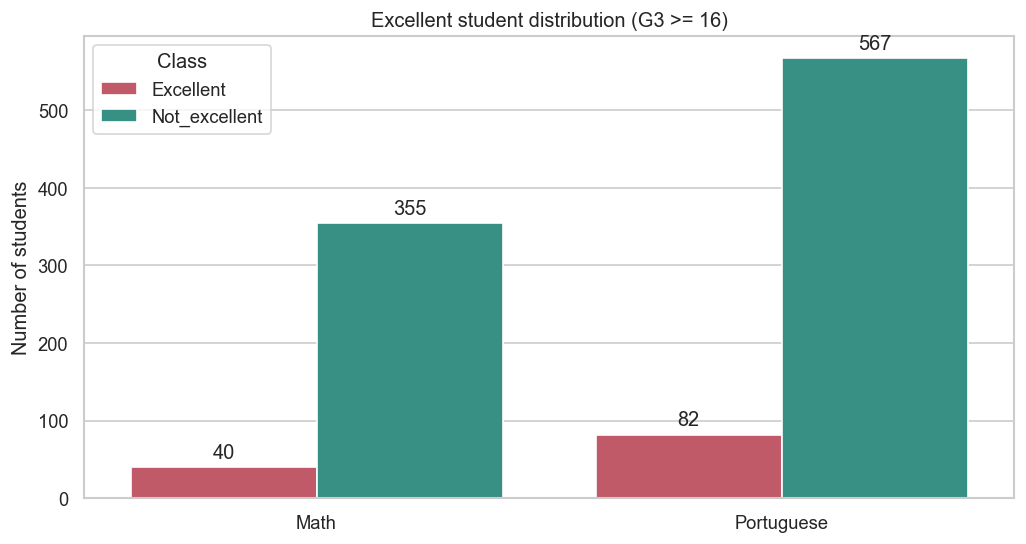

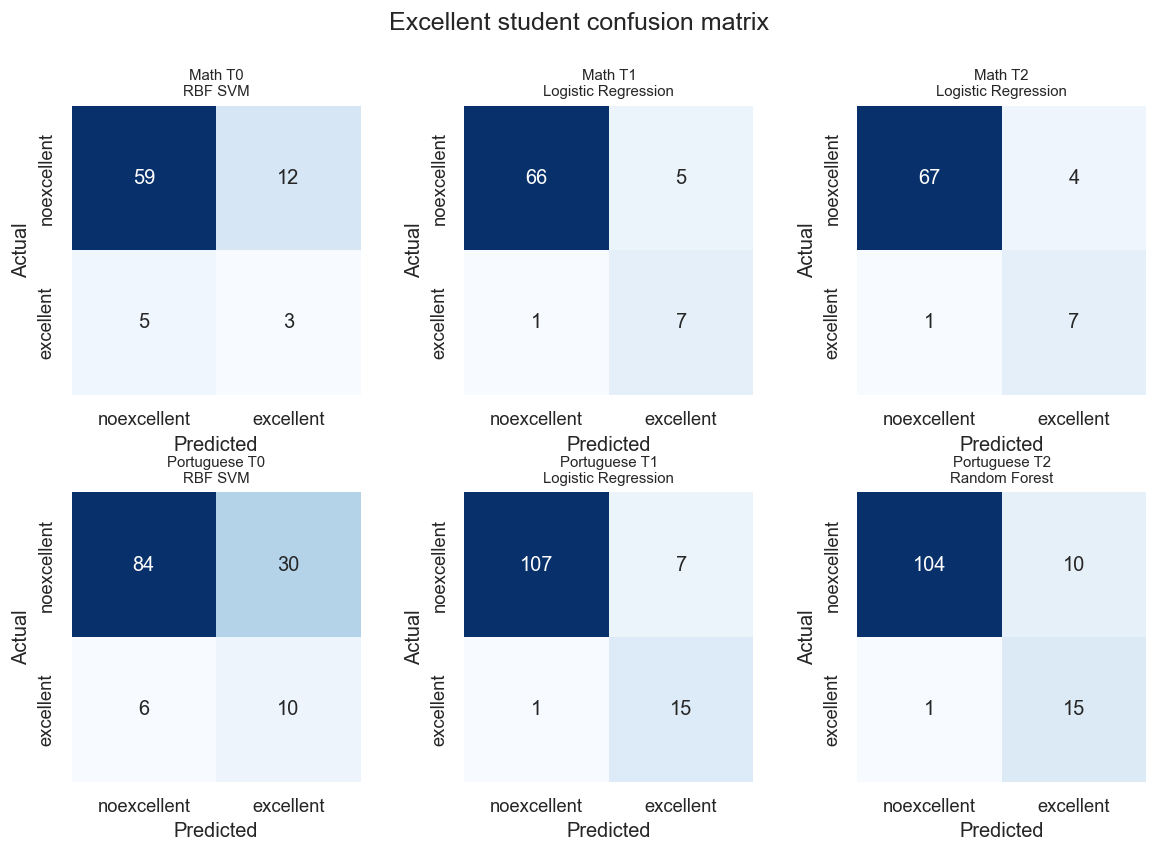

In [24]:
distribution_long = q8_distribution.melt(
    id_vars="Course",value_vars=["Excellent", "Not_excellent"],var_name="Class",value_name="Count",
)
plt.figure(figsize=(10,5))
ax= sns.barplot(data=distribution_long,x="Course",y="Count",hue="Class",palette=["#D1495B","#2A9D8F"],)
for container in ax.containers:
    ax.bar_label(container, padding=3,fontsize=12)
ax.set_title("Excellent student distribution (G3 >= 16)")
ax.set_xlabel("")
ax.set_ylabel("Number of students")
plt.show()

fig,axes = plt.subplots(2,3,figsize=(10,7))
for row_index, course in enumerate(["Math", "Portuguese"]):
    for column_index, scenario in enumerate(["T0", "T1", "T2"]):
        selected_predictions = q8_prediction_tables[(course, scenario)]
        model_name = selected_predictions["Model"].iloc[0]
        matrix = confusion_matrix(
            selected_predictions["Actual_Excellent"],
            selected_predictions["Predicted_Excellent"],
            labels=[0,1],
        )
        sns.heatmap(
            matrix,
            annot=True,fmt="d",cmap="Blues",cbar=False,square=True,
            xticklabels=["noexcellent", "excellent"],yticklabels=["noexcellent", "excellent"],
            ax=axes[row_index,column_index],
        )
        axes[row_index, column_index].set_title(f"{course} {scenario}\n{model_name}",fontsize=9,)
        axes[row_index, column_index].set_xlabel("Predicted")
        axes[row_index, column_index].set_ylabel("Actual")
fig.suptitle("Excellent student confusion matrix",y=1.001,fontsize=15,)
plt.tight_layout()
plt.show()

<div align="right">

## پرسش 9
</div>

In [25]:
q9_distribution_rows = []
q9_result_tables =[]
q9_prediction_tables= []
q9_splits ={}
for course,frame in datasets.items():
    target_q9= (frame["G3"]<frame["G1"]).astype(int)
    q9_splits[course] = flexible_split(target_q9,seed=RANDOM_STATE,)
    q9_distribution_rows.append({
        "Course": course,"Performance_drop": int(target_q9.sum()),"No_drop": int((target_q9 == 0).sum()),
        "Drop_rate": float(target_q9.mean()),"Definition": "G3 < G1",
    })
    result_table, _, prediction_table= train_and_evaluate_task(
        frame=frame,target=target_q9,task_name="Performance Drop After G1",
        course=course,splits=q9_splits[course],
    )
    q9_result_tables.append(result_table)
    q9_prediction_tables.append(prediction_table)

q9_distribution= pd.DataFrame(q9_distribution_rows)
q9_all_results =pd.concat(q9_result_tables,ignore_index=True,)
q9_predictions= (pd.concat(q9_prediction_tables,ignore_index=True,)
    .rename(columns={
        "Actual_Risk": "Actual Drop","Predicted_Risk": "Predicted Drop","Risk_probability": "Drop probability",
    }))

q9_selected= select_by_validation(q9_all_results)

print("Performance Drop class distribution:")
print(q9_distribution.to_string(index=False,formatters={"Drop_rate": "{:.3f}".format,},))
print("\nValidation selected models:")
print(q9_selected[[
        "Course","Scenario","Model","Validation_F1","Validation_Balanced_Accuracy",
        "Accuracy","Balanced_Accuracy","Precision","Recall","F1","ROC_AUC","PR_AUC","FN","TP",
    ]]
    .round(3).to_string(index=False)
)

Performance Drop class distribution:
    Course  Performance_drop  No_drop Drop_rate Definition
      Math               159      236     0.403    G3 < G1
Portuguese               120      529     0.185    G3 < G1

Validation selected models:
    Course Scenario               Model  Validation_F1  Validation_Balanced_Accuracy  Accuracy  Balanced_Accuracy  Precision  Recall    F1  ROC_AUC  PR_AUC  FN  TP
      Math       T0       Random Forest          0.508                         0.607     0.557              0.528      0.444   0.375 0.407    0.566   0.525  20  12
      Math       T1             RBF SVM          0.457                         0.516     0.519              0.536      0.435   0.625 0.513    0.583   0.487  12  20
      Math       T2 Logistic Regression          0.636                         0.690     0.772              0.769      0.706   0.750 0.727    0.830   0.777   8  24
Portuguese       T0 Logistic Regression          0.326                         0.562     0.608       

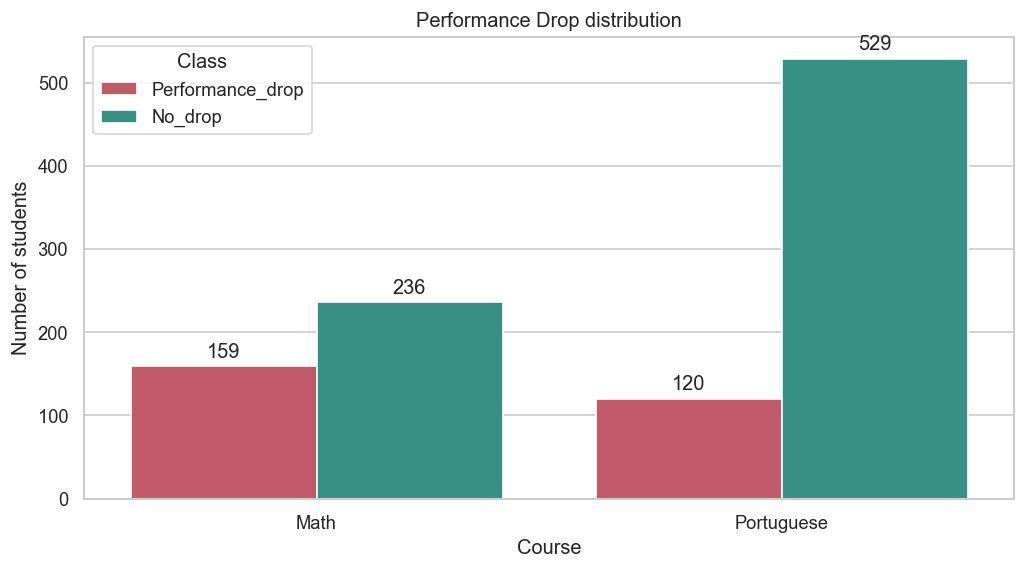

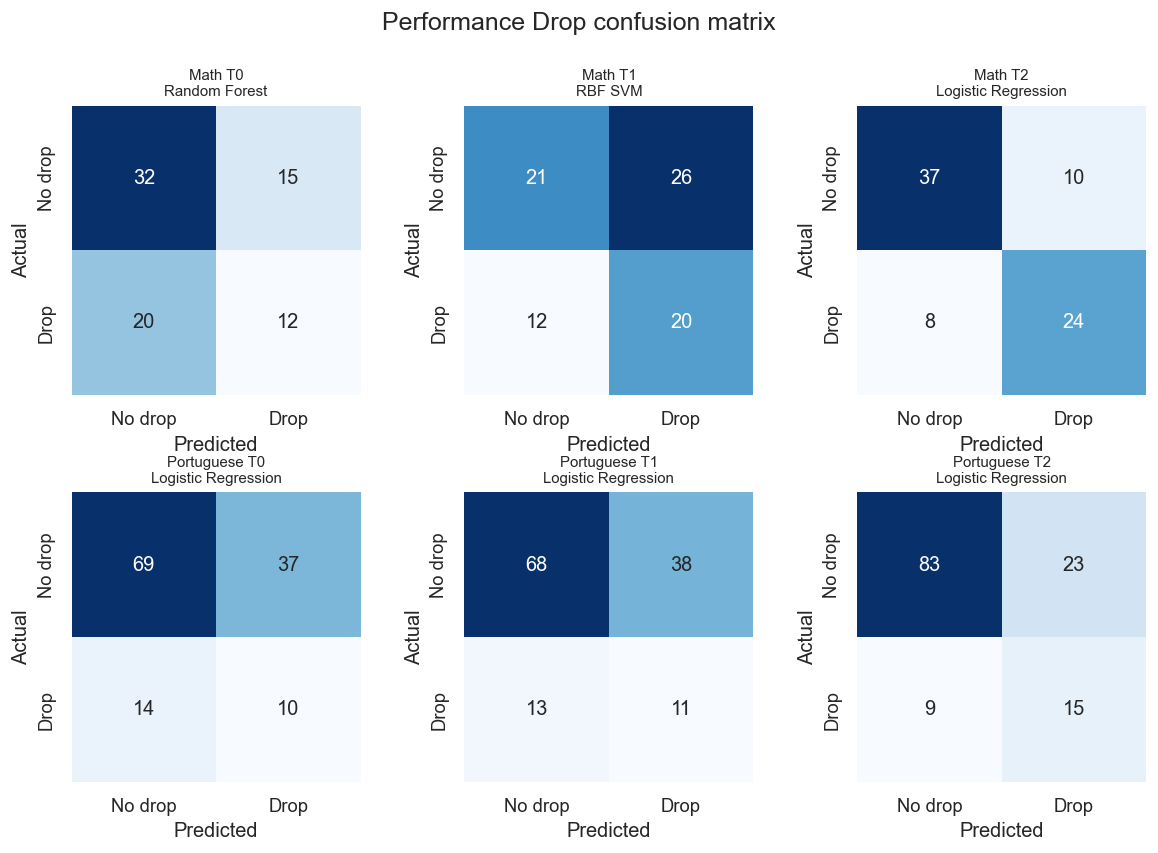

In [26]:
q9_prediction_tables = {}
for course in datasets:
    for scenario in SCENARIOS:
        selected_model= q9_selected[
            (q9_selected["Course"] == course)& (q9_selected["Scenario"] == scenario)
        ].iloc[0]["Model"]
        selected_predictions = q9_predictions[
            (q9_predictions["Course"] ==course)& (q9_predictions["Scenario"] == scenario)& (q9_predictions["Model"]== selected_model)
        ].sort_values("Student_position").reset_index(drop=True)
        q9_prediction_tables[(course, scenario)] = selected_predictions
        matrix = confusion_matrix(selected_predictions["Actual Drop"],selected_predictions["Predicted Drop"],labels=[0,1],)

q9_distribution_long = q9_distribution.melt(
    id_vars="Course",value_vars=["Performance_drop","No_drop",],
    var_name="Class",value_name="Count",
)
plt.figure(figsize=(10,5))
ax = sns.barplot(
    data=q9_distribution_long,x="Course",y="Count",
    hue="Class",palette=["#D1495B","#2A9D8F",],
)
for c in ax.containers:ax.bar_label(c,padding=3,fontsize=12,)
ax.set_title("Performance Drop distribution")
ax.set_ylabel("Number of students")
plt.show()

fig,axes = plt.subplots(2,3,figsize=(10, 7),)
for row_index,course in enumerate(["Math","Portuguese",]):
    for column_index,scenario in enumerate([ "T0","T1","T2",]):
        selected_predictions = (q9_prediction_tables[(course, scenario)])
        model_name= (selected_predictions["Model"].iloc[0])
        matrix = confusion_matrix(selected_predictions["Actual Drop"],selected_predictions["Predicted Drop"],labels=[0,1],)
        sns.heatmap(
            matrix,
            annot=True,fmt="d",cmap="Blues",cbar=False,square=True,
            xticklabels=["No drop","Drop",],
            yticklabels=["No drop","Drop",],
            ax=axes[row_index,column_index,],
        )
        axes[row_index,column_index,].set_title(f"{course} {scenario}\n{model_name}",fontsize=9,)
        axes[row_index,column_index,].set_xlabel("Predicted")
        axes[row_index,column_index,].set_ylabel("Actual")
fig.suptitle("Performance Drop confusion matrix",y=1.001,fontsize=15,)
plt.tight_layout()
plt.show()

<div align="right">

## پرسش 10
</div>

In [27]:
q10_distribution_rows = []
q10_result_tables =[]
q10_prediction_tables = []
q10_splits= {}
Weak_frames= {}
for course,frame in datasets.items():
    weak_frame= frame.loc[frame["G1"] < 10].copy()
    target_q10 =(weak_frame["G3"]>= 10).astype(int)
    Weak_frames[course] = weak_frame
    q10_splits[course]= flexible_split(target_q10,seed=RANDOM_STATE +10,)
    q10_distribution_rows.append({
        "Course": course,"Weak_in_G1": int(len(weak_frame)),
        "Recovered": int(target_q10.sum()),"Not_recovered": int((target_q10 == 0).sum()),
        "Recovery_rate": float(target_q10.mean()),
        })

    (result_table,_,prediction_table,) = train_and_evaluate_task(
            frame=weak_frame,target=target_q10,task_name="Recovery_After_Weak_G1",course=course,splits=q10_splits[course],
        )
    q10_result_tables.append(result_table)
    q10_prediction_tables.append(prediction_table)
q10_distribution = pd.DataFrame(q10_distribution_rows)
q10_all_results = pd.concat(q10_result_tables,ignore_index=True,)
q10_predictions = (pd.concat(q10_prediction_tables,ignore_index=True,).rename(columns={
        "Actual_Risk": "Actual_Recovery","Predicted_Risk": "Predicted_Recovery","Risk_probability": "Recovery_probability",
    })
)
q10_selected = select_by_validation(q10_all_results)

print("Recovery class distribution in G1 < 10:")
print(q10_distribution.to_string(index=False,formatters={"Recovery_rate": "{:.3f}".format,},))
print("\nValidation selected models:")
print(q10_selected[[
        "Course","Scenario","Model","Validation_F1","Validation_Balanced_Accuracy",
        "Accuracy","Balanced_Accuracy","Precision","Recall","F1","ROC_AUC","PR_AUC","FN","TP",
    ]]
    .round(3).to_string(index=False)
)

Recovery class distribution in G1 < 10:
    Course  Weak_in_G1  Recovered  Not_recovered Recovery_rate
      Math         142         38            104         0.268
Portuguese         157         69             88         0.439

Validation selected models:
    Course Scenario               Model  Validation_F1  Validation_Balanced_Accuracy  Accuracy  Balanced_Accuracy  Precision  Recall    F1  ROC_AUC  PR_AUC  FN  TP
      Math       T0 Logistic Regression          0.556                         0.714     0.724              0.693      0.500   0.625 0.556    0.714   0.465   3   5
      Math       T1             RBF SVM          0.667                         0.810     0.759              0.756      0.545   0.750 0.632    0.762   0.641   2   6
      Math       T2       Random Forest          0.800                         0.881     0.828              0.804      0.667   0.750 0.706    0.863   0.736   2   6
Portuguese       T0             RBF SVM          0.538                         0.603  

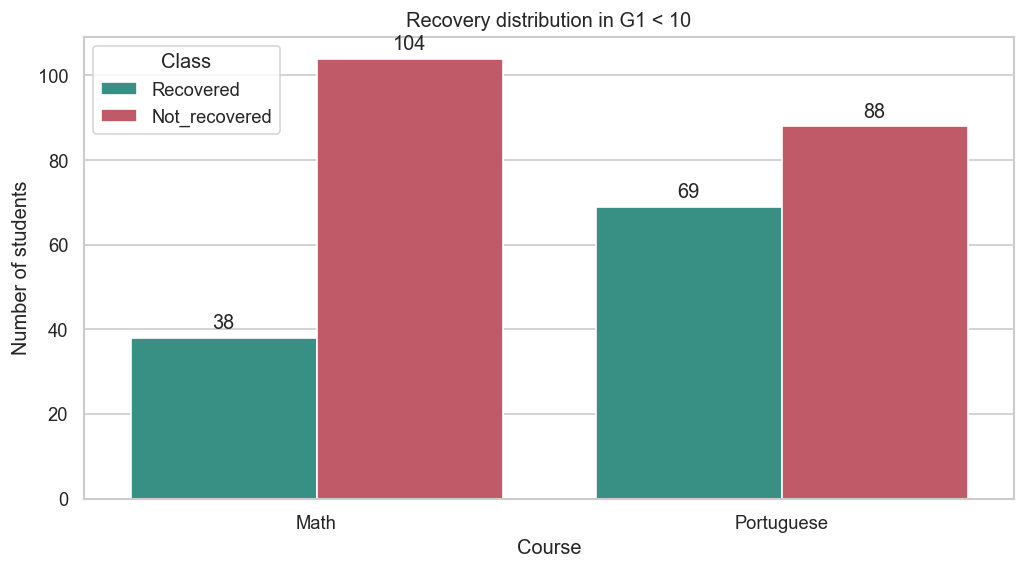

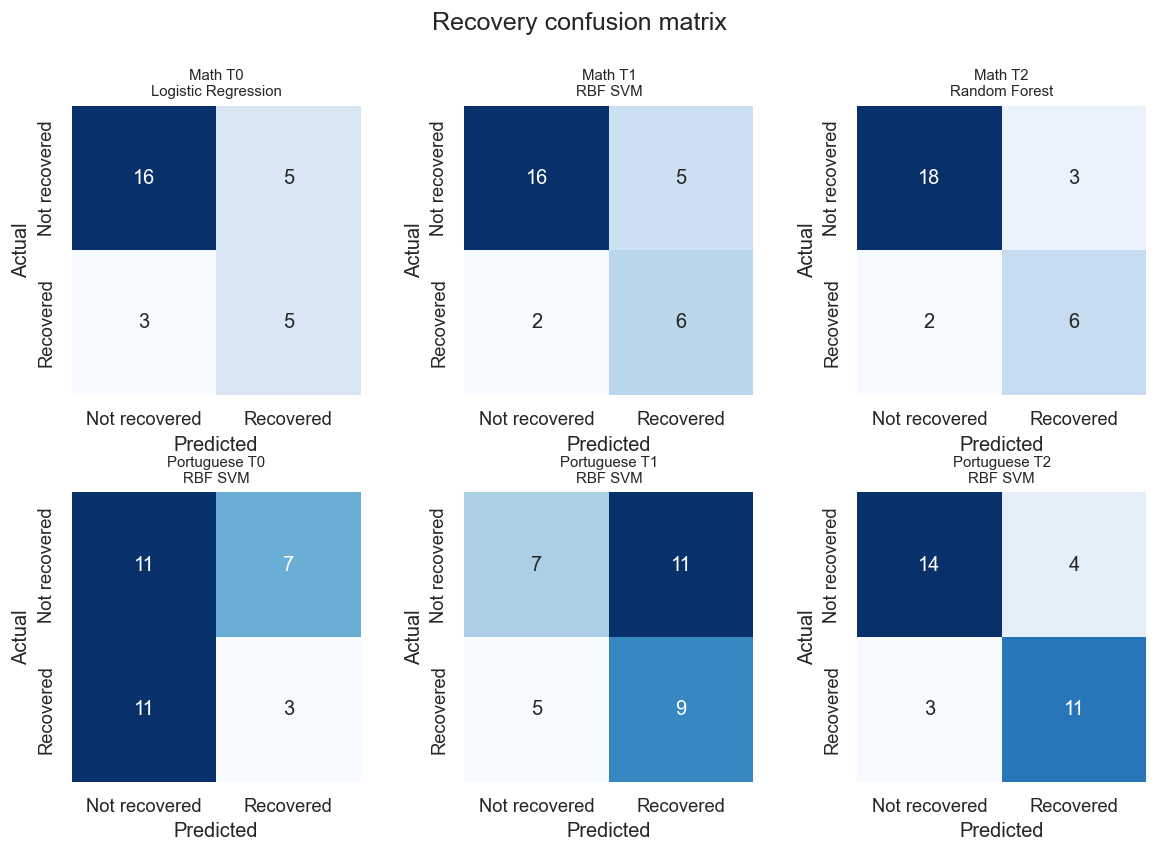

In [28]:
q10_prediction_tables = {}
for course in datasets:
    for scenario in SCENARIOS:
        selected_model= q10_selected[(q10_selected["Course"] == course)& (q10_selected["Scenario"] == scenario)].iloc[0]["Model"]
        selected_predictions= q10_predictions[
            (q10_predictions["Course"] == course)& (q10_predictions["Scenario"]== scenario)& (q10_predictions["Model"] == selected_model)
        ].sort_values("Student_position").reset_index(drop=True)
        q10_prediction_tables[(course, scenario)] =selected_predictions
        matrix= confusion_matrix(
            selected_predictions["Actual_Recovery"],selected_predictions["Predicted_Recovery"],labels=[0,1],
        )
q10_distribution_long = q10_distribution.melt(
    id_vars="Course",value_vars=["Recovered","Not_recovered",],
    var_name="Class",value_name="Count",
)

plt.figure(figsize=(10, 5))
ax= sns.barplot(
    data=q10_distribution_long,x="Course",y="Count",
    hue="Class",palette=["#2A9D8F","#D1495B",],
)
for c in ax.containers:
    ax.bar_label(c,padding=3,fontsize=12,)
ax.set_title("Recovery distribution in G1 < 10")
ax.set_ylabel("Number of students")
plt.show()

fig, axes = plt.subplots(2,3,figsize=(10,7),)
for row_index, course in enumerate(["Math","Portuguese",]):
    for column_index, scenario in enumerate(SCENARIOS):
        selected_predictions = (q10_prediction_tables[(course, scenario)])
        model_name = (selected_predictions["Model"].iloc[0])
        matrix = confusion_matrix(
            selected_predictions["Actual_Recovery"],selected_predictions["Predicted_Recovery"],labels=[0, 1],
        )
        sns.heatmap(
            matrix,
            annot=True,fmt="d",cmap="Blues",cbar=False,square=True,
            xticklabels=["Not recovered","Recovered",],yticklabels=["Not recovered","Recovered",],
            ax=axes[row_index,column_index,],
        )
        axes[row_index,column_index,].set_title(f"{course} {scenario}\n{model_name}",fontsize=9,)
        axes[row_index,column_index,].set_xlabel("Predicted")
        axes[row_index,column_index,].set_ylabel("Actual")
fig.suptitle("Recovery confusion matrix",y=1.001,fontsize=15,)
plt.tight_layout()
plt.show()

<div align="right">

## پرسش 11
</div>

<div align="right">

##### انتخاب دانش آموزان و معیار انتخاب
</div>

In [29]:
CAPACITY_FRACTIONS = np.arange(0.05,0.51,0.15)
REFERENCE_CAPACITY = 0.2   
q11_ranking_tables = {}
q11_ranking_rows =[]
for course in datasets:
    for scenario in SCENARIOS:
        selected_model= best_by_scenario[(best_by_scenario["Course"] == course)& (best_by_scenario["Scenario"] == scenario)].iloc[0]["Model"]
        ranking =q1_predictions_df[
            (q1_predictions_df["Course"] == course)& (q1_predictions_df["Scenario"] == scenario)& (q1_predictions_df["Model"] == selected_model)
        ].copy()
        ranking = ranking.sort_values(["Risk_probability", "Student_position"],ascending=[False,True],).reset_index(drop=True)
        ranking["Student_number"]= (ranking["Student_position"] +1)
        ranking["Risk_rank"] = np.arange(1,len(ranking) +1,)
        ranking["Scenario_description"] = (SCENARIOS[scenario]["description"])
        q11_ranking_tables[(course,scenario)] =ranking
        q11_ranking_rows.append(ranking)

q11_rankings = pd.concat(q11_ranking_rows,ignore_index=True,)
print("Top 4 students with the highest predicted risk:")
print(q11_rankings.groupby(["Course", "Scenario"],group_keys=False,)
    .head(4)[[
        "Course","Scenario","Model",
        "Student_number","Risk_rank","Risk_probability",
    ]]
    .round(3)
    .to_string(index=False)
)

Top 4 students with the highest predicted risk:
    Course Scenario               Model  Student_number  Risk_rank  Risk_probability
      Math       T0 Logistic Regression             151          1             0.979
      Math       T0 Logistic Regression             279          2             0.970
      Math       T0 Logistic Regression              73          3             0.962
      Math       T0 Logistic Regression             387          4             0.922
      Math       T1 Logistic Regression             387          1             0.999
      Math       T1 Logistic Regression             279          2             0.997
      Math       T1 Logistic Regression             371          3             0.996
      Math       T1 Logistic Regression             151          4             0.995
      Math       T2 Logistic Regression             132          1             1.000
      Math       T2 Logistic Regression             129          2             1.000
      Math       

<div align="right">

##### اثر افزایش تعداد نفرات

In [30]:
def capacity_metrics(ranking,capacity_fraction,):
    total_students= len(ranking)
    selected_students_count = max(1,int(np.ceil(total_students* capacity_fraction)),)
    selected_students= ranking.head(selected_students_count)
    total_at_risk =int(ranking["Actual_Risk"].sum())
    selected_at_risk = int(selected_students["Actual_Risk"].sum())
    selected_not_at_risk = int(selected_students_count- selected_at_risk)
    missed_at_risk = int(total_at_risk- selected_at_risk)
    precision_at_k= (selected_at_risk/ selected_students_count)
    recall_at_k= (selected_at_risk / total_at_risk if total_at_risk > 0 else np.nan)
    risk_rate= (total_at_risk /total_students)
    lift_at_k = (precision_at_k / risk_rate if risk_rate > 0 else np.nan)
    return {
        "Capacity_fraction": float(capacity_fraction),
        "Selected_students":int(selected_students_count),
        "Total_students": int(total_students),
        "Total_at_risk":int(total_at_risk),
        "Selected_at_risk":int(selected_at_risk),
        "Selected_not_at_risk": int(selected_not_at_risk),
        "Missed_at_risk": int(missed_at_risk),
        "Precision_at_K": float(precision_at_k),
        "Recall_at_K": float(recall_at_k),
        "Lift_at_K": float(lift_at_k),
    }

q11_capacity_rows = []
for (course,scenario,), ranking in q11_ranking_tables.items():
    for capacity_fraction in (CAPACITY_FRACTIONS):
        q11_capacity_rows.append({
            "Course": course,"Scenario": scenario,
            "Scenario_description": (SCENARIOS[scenario]["description"]),
            "Model":ranking["Model"].iloc[0],
            **capacity_metrics(ranking,capacity_fraction,),
        })

q11_capacity_results = (pd.DataFrame(q11_capacity_rows).sort_values(["Course","Scenario","Capacity_fraction",]).reset_index(drop=True))
q11_capacity_results["Students_added"] =(
    q11_capacity_results.groupby(["Course","Scenario",])["Selected_students"].diff().fillna(q11_capacity_results["Selected_students"]).astype(int)
)
print("Effect of increasing the capacity:")
print(q11_capacity_results[[
        "Course","Scenario","Capacity_fraction","Selected_students","Selected_at_risk",
        "Missed_at_risk","Precision_at_K","Recall_at_K","Students_added",
    ]]
    .round(3).to_string(index=False)
)

Effect of increasing the capacity:
    Course Scenario  Capacity_fraction  Selected_students  Selected_at_risk  Missed_at_risk  Precision_at_K  Recall_at_K  Students_added
      Math       T0               0.05                  4                 4              22           1.000        0.154               4
      Math       T0               0.20                 16                 9              17           0.562        0.346              12
      Math       T0               0.35                 28                14              12           0.500        0.538              12
      Math       T0               0.50                 40                19               7           0.475        0.731              12
      Math       T1               0.05                  4                 4              22           1.000        0.154               4
      Math       T1               0.20                 16                14              12           0.875        0.538              12
      

<div align="right">

##### انتخاب بهترین سناریو زمانی

In [31]:
q11_reference_results = (
    q11_capacity_results[ np.isclose(q11_capacity_results["Capacity_fraction"],REFERENCE_CAPACITY,)].copy()
)
q11_reference_results= (
    q11_reference_results.sort_values(
        ["Course","Recall_at_K","Precision_at_K","Lift_at_K",],ascending=[True,False,False,False,],).reset_index(drop=True)
)
q11_best_scenario= (q11_reference_results.groupby("Course",as_index=False,).head(1).reset_index(drop=True))
q11_student_rows =[]
for (course,scenario,), ranking in q11_ranking_tables.items():
    selected_students_count = max(1,int(np.ceil(len(ranking)* REFERENCE_CAPACITY)),)
    selected_students = (ranking.head(selected_students_count).copy())
    selected_students["Capacity_fraction"] = REFERENCE_CAPACITY
    selected_students["Selected_students"]= selected_students_count
    q11_student_rows.append(selected_students)

q11_selected_students = pd.concat(q11_student_rows,ignore_index=True,)

print(f"Scenario comparison at "f"{REFERENCE_CAPACITY:.0%} capacity:")
print(q11_reference_results[[
        "Course","Scenario","Model","Selected_students","Selected_at_risk",
        "Missed_at_risk","Precision_at_K","Recall_at_K","Lift_at_K",
    ]]
    .round(3).to_string(index=False)
)

print(f"\nStrongest scenario at "f"{REFERENCE_CAPACITY:.0%} capacity:")
print(q11_best_scenario[[
        "Course","Scenario","Model","Selected_students","Selected_at_risk",
        "Missed_at_risk","Precision_at_K","Recall_at_K","Lift_at_K",
    ]]
    .round(3).to_string(index=False)
)

print(f"\nStudents selected at "f"{REFERENCE_CAPACITY:.0%} capacity:")
print(q11_selected_students[[
        "Course","Scenario","Model",
        "Risk_rank","Risk_probability",
    ]]
    .round(3).to_string(index=False)
)

Scenario comparison at 20% capacity:
    Course Scenario               Model  Selected_students  Selected_at_risk  Missed_at_risk  Precision_at_K  Recall_at_K  Lift_at_K
      Math       T2 Logistic Regression                 16                16              10           1.000        0.615      3.038
      Math       T1 Logistic Regression                 16                14              12           0.875        0.538      2.659
      Math       T0 Logistic Regression                 16                 9              17           0.562        0.346      1.709
Portuguese       T2       Random Forest                 26                20               0           0.769        1.000      5.000
Portuguese       T1       Random Forest                 26                17               3           0.654        0.850      4.250
Portuguese       T0             RBF SVM                 26                14               6           0.538        0.700      3.500

Strongest scenario at 20% capac

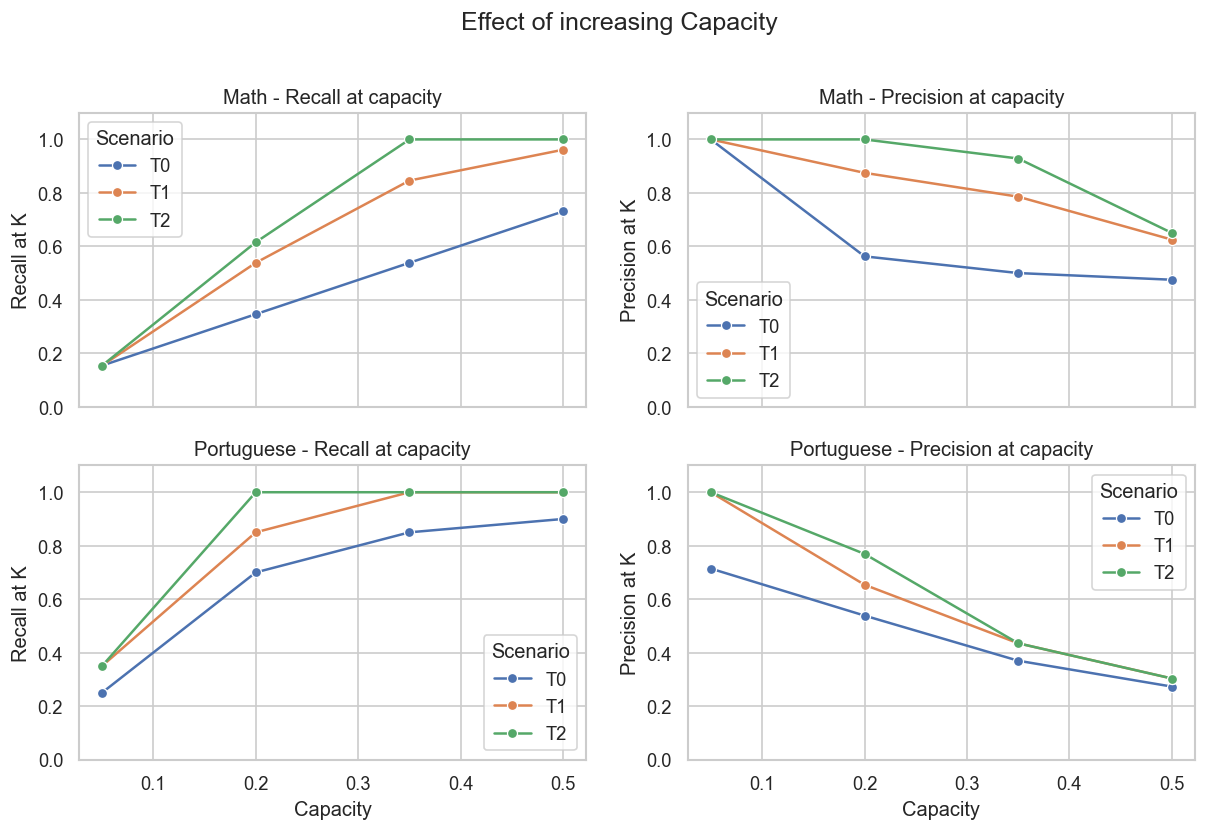

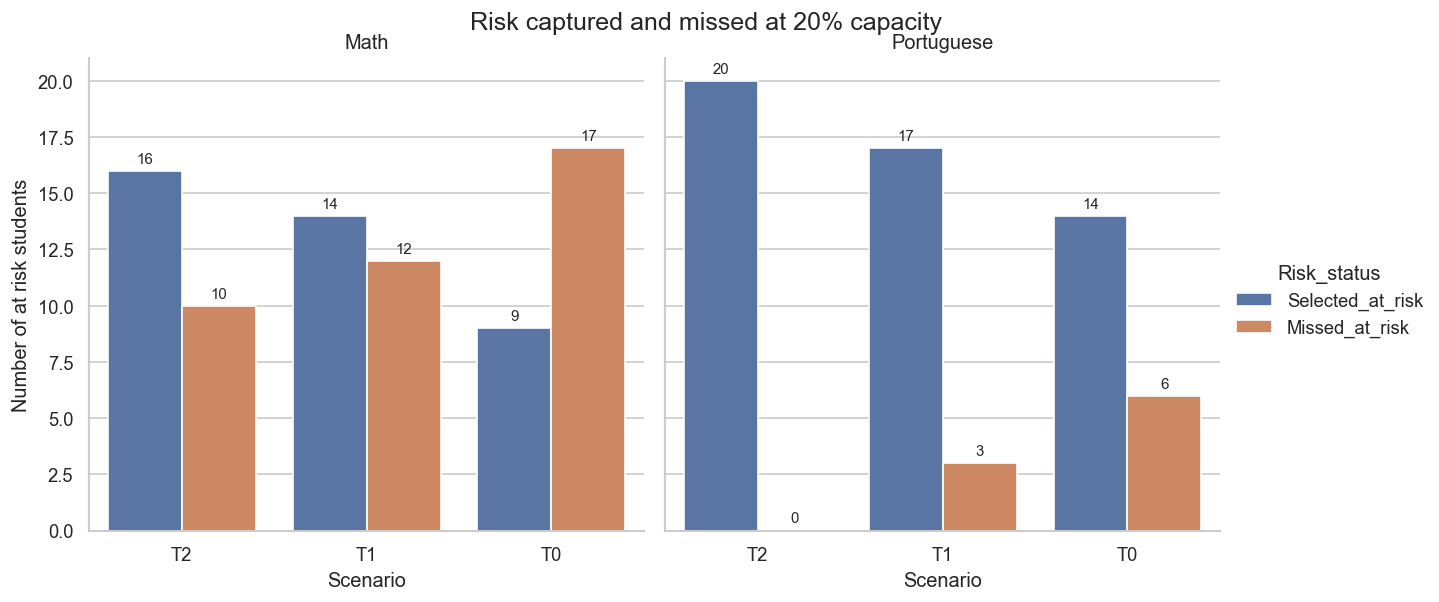

In [32]:
fig, axes = plt.subplots(2,2,figsize=(12,7),sharex=True,)
for row_index,course in enumerate(["Math","Portuguese",]):
    chart_data = q11_capacity_results[q11_capacity_results["Course"]== course].copy()
    sns.lineplot(
        data=chart_data,x="Capacity_fraction",y="Recall_at_K",
        hue="Scenario",marker="o",ax=axes[row_index, 0],
    )
    axes[row_index,0].set_title(f"{course} - Recall at capacity")
    axes[row_index,0].set_xlabel("Capacity")
    axes[row_index, 0].set_ylabel("Recall at K")
    axes[row_index, 0].set_ylim(0,1.1,)
    sns.lineplot(
        data=chart_data,x="Capacity_fraction",y="Precision_at_K",
        hue="Scenario",marker="o",ax=axes[row_index, 1],
    )
    axes[row_index,1].set_title(f"{course} - Precision at capacity")
    axes[row_index, 1].set_xlabel("Capacity")
    axes[row_index, 1].set_ylabel("Precision at K")
    axes[row_index, 1].set_ylim(0,1.1,)

fig.suptitle("Effect of increasing Capacity",y=1.001,fontsize=15,)
plt.show()

q11_reference_long = (q11_reference_results.melt(
        id_vars=["Course","Scenario","Model","Selected_students",],
        value_vars=["Selected_at_risk","Missed_at_risk",],
        var_name="Risk_status",value_name="Count",)
)
g= sns.catplot(
    data=q11_reference_long,x="Scenario",y="Count",hue="Risk_status",
    col="Course",kind="bar",height=5,aspect=1.05,
)
for ax in g.axes.flat:
    for c in ax.containers:
        ax.bar_label(c,padding=3,fontsize=9,)

g.set_axis_labels("Scenario","Number of at risk students",)
g.set_titles("{col_name}")
g.fig.suptitle(f"Risk captured and missed at "f"{REFERENCE_CAPACITY:.0%} capacity",y=1.001,fontsize=15,)
plt.show()

<div align="right">

## پرسش 12

</div>

In [33]:
Q12_COST_SETTINGS = {
    "Leaving_cost_2": {"Help_cost": 1, "Leaving_cost": 2,},
    "Leaving_cost_5": {"Help_cost": 1,"Leaving_cost": 5,},
    "Leaving_cost_8": {"Help_cost": 1,"Leaving_cost": 8,},
}

Q12_REFERENCE = "Leaving_cost_5"
Q12_THRESHOLD_GRID = np.linspace(0.01,0.99,199,)
def q12_cost_values(y_true,y_predict,help_cost,leaving_cost,):
    TN, FP,FN, TP= confusion_matrix(y_true,y_predict,labels=[0, 1],).ravel()
    selected_students = int(TP +FP)
    help_cost_total= (help_cost * selected_students)
    leaving_cost_total = (leaving_cost* FN)
    total_cost= (help_cost_total+ leaving_cost_total)
    return {
        "TN": int(TN),"FP": int(FP),"FN": int(FN),"TP": int(TP),
        "Selected_students":selected_students,
        "Help_cost_total":float(help_cost_total),"Leaving_cost_total": float(leaving_cost_total),
        "Total_cost":float(total_cost),"Average_cost_per_student": float(total_cost/ len(y_true)),
    }
q12_validation_rows = []
q12_result_rows= []
for course,frame in datasets.items():
    y = frame["Risk"].astype(int)
    (train_pos,validation_pos,test_pos,) = course_splits[course]
    for scenario in SCENARIOS:
        selected =best_by_scenario[(best_by_scenario["Course"]== course)& (best_by_scenario["Scenario"]== scenario)].iloc[0]
        model_name= selected["Model"]
        X, _ = scenario_xy(frame,scenario,)
        X_train =X.iloc[train_pos]
        y_train =y.iloc[train_pos]
        X_validation = X.iloc[validation_pos]
        y_validation= y.iloc[validation_pos]
        X_test= X.iloc[test_pos]
        y_test = y.iloc[test_pos]
        estimator = (estimator_from_selected_configuration(model_name,selected["Selected_parameters"],))
        validation_model = Pipeline([("preprocess",preprocessor(X_train),),("model",estimator,),])
        validation_model.fit(X_train,y_train,)
        validation_probability= (probability_of_risk(validation_model, X_validation,) )
        X_train_validation = pd.concat([  X_train,X_validation,],axis=0,)
        y_train_validation = pd.concat([y_train,y_validation,],axis=0,)
        final_estimator = (estimator_from_selected_configuration(model_name,selected["Selected_parameters"],))
        final_model = Pipeline([("preprocess",preprocessor(X_train_validation),),("model",final_estimator,),])
        final_model.fit(X_train_validation,y_train_validation,)
        test_probability= (probability_of_risk(final_model,X_test,))
        for (setting_name,costs,) in Q12_COST_SETTINGS.items():
            help_cost = costs["Help_cost"]
            leaving_cost = costs["Leaving_cost"]
            setting_curve_rows = []
            for threshold in (Q12_THRESHOLD_GRID) :
                validation_prediction =(validation_probability>= threshold).astype(int)
                cost_values = (q12_cost_values(y_validation,validation_prediction,help_cost,leaving_cost,))
                curve_row = {
                    "Course":course,"Scenario": scenario,"Model": model_name,
                    "Cost_setting": (setting_name),"Help_cost": (help_cost),
                    "Leaving_cost": (leaving_cost),"Threshold": float(threshold),
                    **cost_values,
                }
                setting_curve_rows.append(curve_row)
                q12_validation_rows.append(curve_row)

            setting_curve = pd.DataFrame(setting_curve_rows)
            best_validation_row= (setting_curve.sort_values(["Total_cost","FN","Selected_students","Threshold",],
                    ascending=[True, True, True,True,],).iloc[0]
            )
            selected_threshold = float(best_validation_row["Threshold"])
            test_prediction_optimal= (test_probability>= selected_threshold).astype(int)
            test_prediction_default = (test_probability>= 0.5).astype(int)
            optimal_cost =(q12_cost_values(y_test,test_prediction_optimal,help_cost, leaving_cost,))
            default_cost= (q12_cost_values(y_test,test_prediction_default,help_cost,leaving_cost,))
            optimal_metrics = (calculate_all_metrics(y_test, test_prediction_optimal,test_probability,))

            q12_result_rows.append({
                "Course": course,"Scenario": scenario,"Model": model_name,
                "Cost_setting": (setting_name),"Help_cost": help_cost,"Leaving_cost": (leaving_cost),
                "Selected_threshold_validation":(selected_threshold),
                "Test_cost_optimal_threshold": (optimal_cost["Total_cost"]),
                "Test_cost_default_0.5": (default_cost["Total_cost"]),
                "Test_cost_reduction": (default_cost["Total_cost"]- optimal_cost["Total_cost"]),
                "Test_cost_reduction_percent": (
                    (default_cost["Total_cost"]- optimal_cost["Total_cost"])/ default_cost["Total_cost"]
                    if default_cost["Total_cost"] > 0
                    else 0 ),
                **{
                    f"Optimal_{key}": value
                    for key, value
                    in optimal_cost.items()
                },
                **{
                    f"Test_{key}": value
                    for key, value
                    in optimal_metrics.items()
                },
            })

q12_validation_cost_curve = (pd.DataFrame(q12_validation_rows))
q12_results = pd.DataFrame( q12_result_rows)
q12_reference_results = (q12_results[q12_results["Cost_setting"]== Q12_REFERENCE].copy())

print("Compare different cost ratios:")
print(q12_results[[
        "Course","Scenario","Cost_setting",
        "Selected_threshold_validation","Test_cost_optimal_threshold",
        "Optimal_Selected_students","Optimal_FN","Optimal_TP",
        "Test_Precision","Test_Recall",
    ]]
    .round(3).to_string(index=False)
)

Compare different cost ratios:
    Course Scenario   Cost_setting  Selected_threshold_validation  Test_cost_optimal_threshold  Optimal_Selected_students  Optimal_FN  Optimal_TP  Test_Precision  Test_Recall
      Math       T0 Leaving_cost_2                          0.911                         48.0                          4          22           4           1.000        0.154
      Math       T0 Leaving_cost_5                          0.411                         74.0                         39           7          19           0.487        0.731
      Math       T0 Leaving_cost_8                          0.411                         95.0                         39           7          19           0.487        0.731
      Math       T1 Leaving_cost_2                          0.579                         33.0                         25           4          22           0.880        0.846
      Math       T1 Leaving_cost_5                          0.421                         46.0

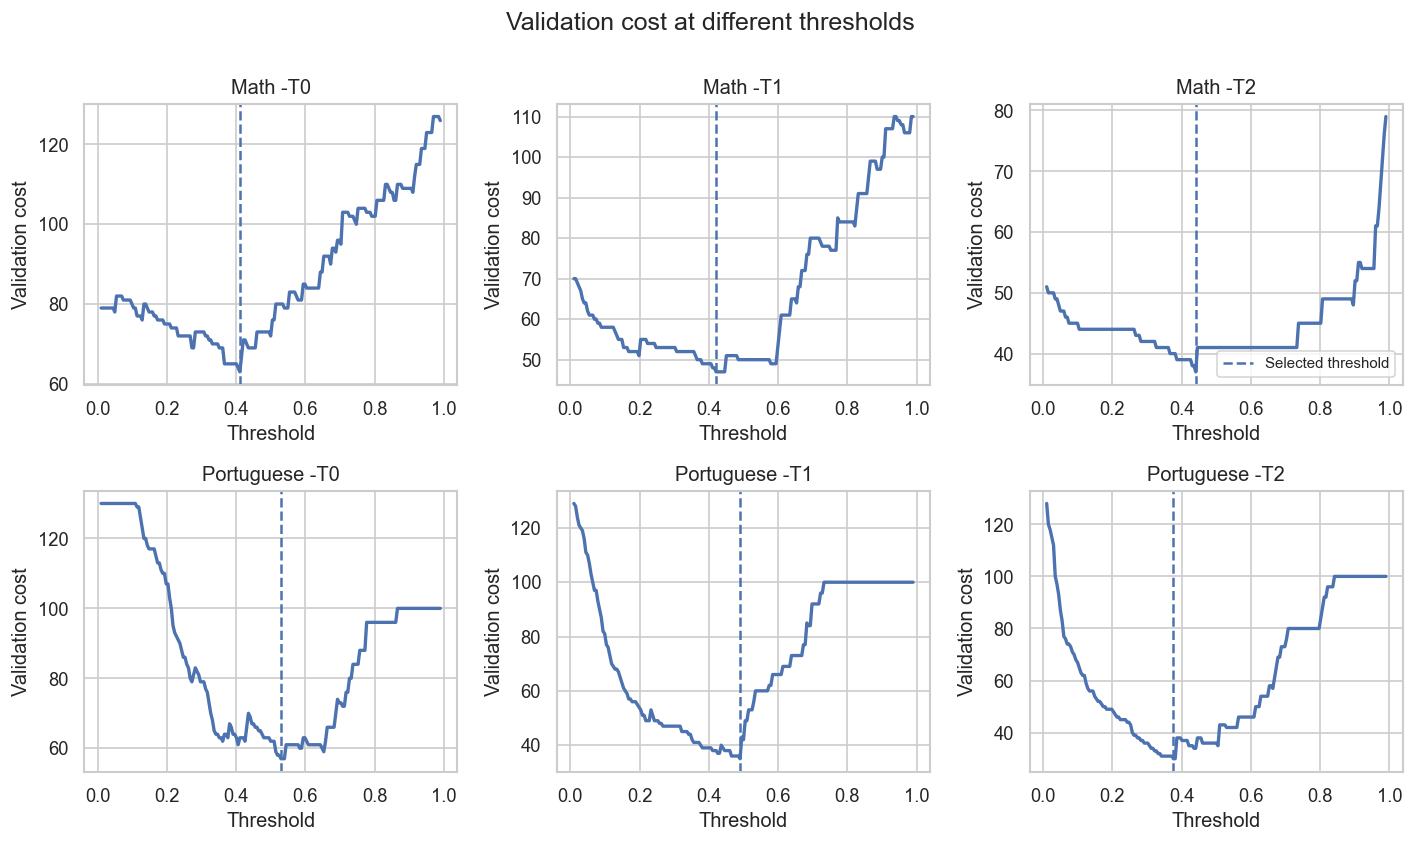

In [34]:
fig, axes = plt.subplots(2,3,figsize=(12,7),)
for row_index, course in enumerate(["Math","Portuguese",]):
    for (column_index,scenario,) in enumerate(["T0","T1","T2",]):
        ax = axes[row_index,column_index,]
        chart_data = (
            q12_validation_cost_curve[
                (q12_validation_cost_curve["Course"]== course)& (q12_validation_cost_curve["Scenario"]== scenario)
                & (q12_validation_cost_curve["Cost_setting"]== Q12_REFERENCE)
            ]
        )
        result_row = (
            q12_reference_results[(q12_reference_results["Course"]== course)
                & (q12_reference_results["Scenario"]== scenario)].iloc[0]
        )
        selected_threshold= (result_row["Selected_threshold_validation"])
        ax.plot(chart_data["Threshold"],chart_data["Total_cost"],linewidth=2,)
        ax.axvline(selected_threshold,linestyle="--",label=("Selected threshold"),)
        ax.set_title(f"{course} -{scenario}")
        ax.set_xlabel("Threshold")
        ax.set_ylabel("Validation cost")
        if (row_index == 0 and column_index == 2):
            ax.legend(fontsize=9)
fig.suptitle("Validation cost at different thresholds",y=1.001,fontsize=15,)
plt.tight_layout()
plt.show()

<div align="right">

## پرسش 13

</div>

In [35]:
summary_rows = []
reliability_rows = []
probability_bins= np.linspace(0,1,6)
for course in ["Math", "Portuguese"]:
    for scenario in ["T0","T1", "T2"]:
        selected_model = best_by_scenario[
            (best_by_scenario["Course"] == course)& (best_by_scenario["Scenario"] == scenario)].iloc[0]["Model"]
        predictions= q1_predictions_df[
            (q1_predictions_df["Course"]== course) & (q1_predictions_df["Scenario"] ==scenario)& (q1_predictions_df["Model"] == selected_model)
        ].copy()
        
        y_true= predictions["Actual_Risk"].to_numpy(dtype=int)
        y_probability= predictions["Risk_probability"].to_numpy(dtype=float)
        summary_rows.append({
            "Course": course,"Scenario": scenario,"Model": selected_model,
            "Observed_risk": y_true.mean(),"Mean_predicted_prob": y_probability.mean(),
            "Brier_score": brier_score_loss(y_true,y_probability,),
        })
        reliability_data = pd.DataFrame({"Actual_Risk": y_true,"Risk_probability": y_probability,})
        reliability_data["Probability_bin"] = pd.cut(reliability_data["Risk_probability"],bins=probability_bins,include_lowest=True,)
        reliability_table =(reliability_data.groupby("Probability_bin",observed=True,).agg(
                Count=("Actual_Risk", "size"),Mean_predicted_prob=("Risk_probability","mean",),
                Observed_risk=("Actual_Risk","mean",),).reset_index()
        )
        reliability_table["Course"]= course
        reliability_table["Scenario"] = scenario
        reliability_table["Model"] =selected_model
        reliability_rows.append(reliability_table)

q13_summary= pd.DataFrame(summary_rows)
q13_reliability = pd.concat(reliability_rows,ignore_index=True,)
print("Raw probability reliability results:")
print(q13_summary.round(3).to_string(index=False))

Raw probability reliability results:
    Course Scenario               Model  Observed_risk  Mean_predicted_prob  Brier_score
      Math       T0 Logistic Regression          0.329                0.470        0.225
      Math       T1 Logistic Regression          0.329                0.354        0.083
      Math       T2 Logistic Regression          0.329                0.359        0.028
Portuguese       T0             RBF SVM          0.154                0.363        0.141
Portuguese       T1       Random Forest          0.154                0.247        0.075
Portuguese       T2       Random Forest          0.154                0.234        0.053


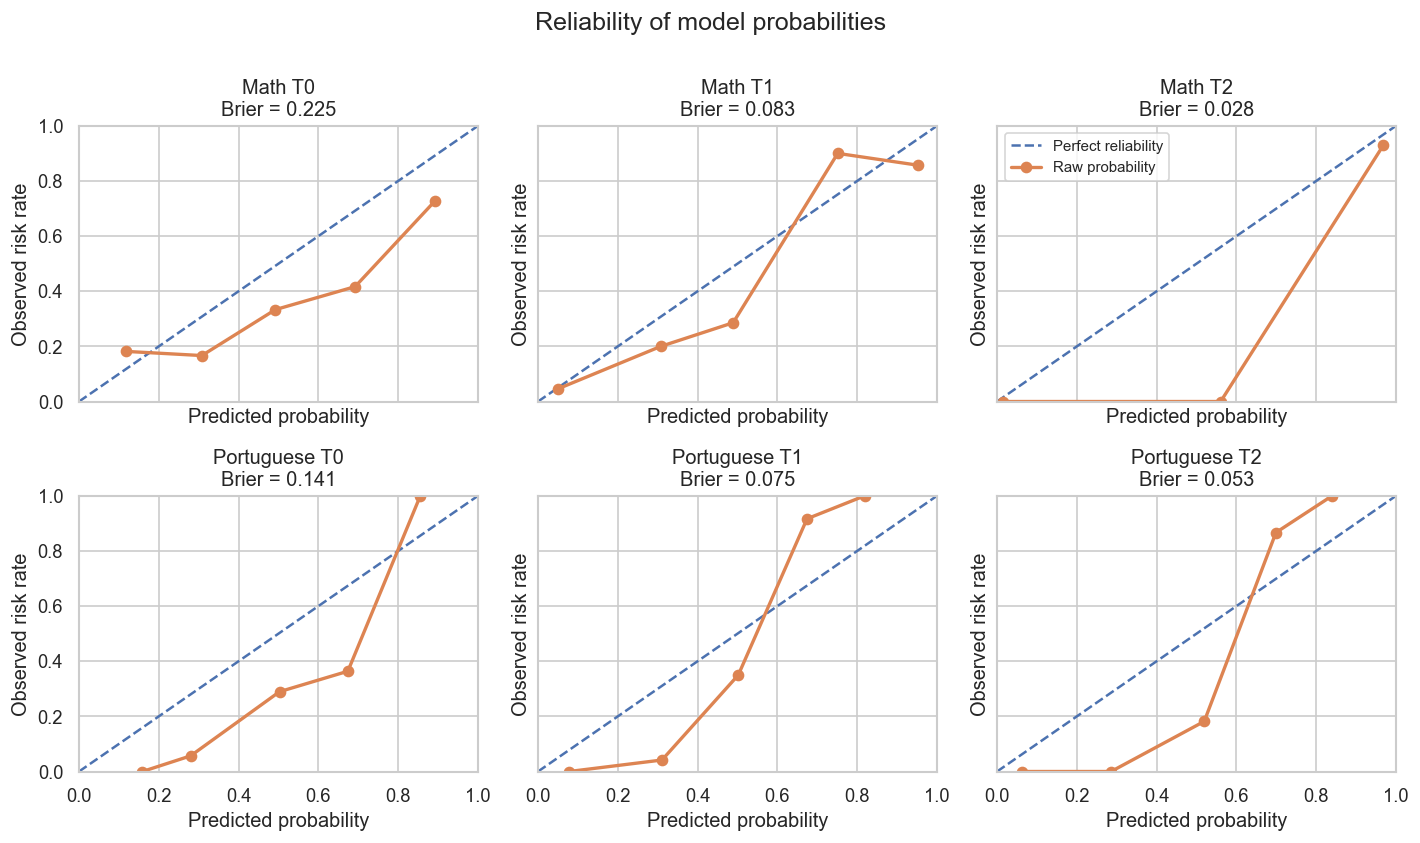

In [36]:
fig, axes = plt.subplots(2,3,figsize=(12,7),sharex=True,sharey=True,)
for row_index, course in enumerate(["Math","Portuguese",]):
    for column_index, scenario in enumerate(["T0","T1","T2",]):
        ax= axes[row_index,column_index,]
        chart_data= q13_reliability[(q13_reliability["Course"] == course)& (q13_reliability["Scenario"]== scenario)]
        summary_row = q13_summary[(q13_summary["Course"] == course)& (q13_summary["Scenario"]== scenario)].iloc[0]
        ax.plot([0,1],[0,1],linestyle="--",label="Perfect reliability",)
        ax.plot(chart_data["Mean_predicted_prob"],chart_data["Observed_risk"],
            marker="o",linewidth=2,label="Raw probability",
        )
        ax.set_title(f"{course} {scenario}\n" f"Brier = "f"{summary_row['Brier_score']:.3f}")
        ax.set_xlabel("Predicted probability")
        ax.set_ylabel("Observed risk rate")
        ax.set_xlim(0, 1)
        ax.set_ylim(0,1)
        if row_index== 0 and column_index == 2:
            ax.legend(fontsize=9)

fig.suptitle("Reliability of model probabilities",fontsize=15,y=1.001,)
plt.tight_layout()
plt.show()

<div align="right">

## پرسش 14

</div>

In [37]:
def fit_q1_selected_model(course,scenario,X,y,):
    selected = best_by_scenario[(best_by_scenario["Course"] == course)& (best_by_scenario["Scenario"]== scenario)].iloc[0]
    train_pos, validation_pos,test_pos= (course_splits[course])
    train_validation_pos= np.concatenate([train_pos,validation_pos,])
    estimator = (estimator_from_selected_configuration(selected["Model"],selected["Selected_parameters"],))
    model= Pipeline([("preprocess",preprocessor(X.iloc[train_validation_pos]),),("model",estimator,),])
    model.fit(X.iloc[train_validation_pos],y.iloc[train_validation_pos],)
    return model, selected, test_pos

    Course Scenario               Model      Feature_set  Balanced_Accuracy  Recall    F1  PR_AUC  FN  TP
      Math       T0 Logistic Regression    With absences              0.628   0.615 0.525   0.618  10  16
      Math       T0 Logistic Regression Without absences              0.638   0.615 0.533   0.613  10  16
Portuguese       T0             RBF SVM    With absences              0.798   0.750 0.577   0.583   5  15
Portuguese       T0             RBF SVM Without absences              0.784   0.750 0.545   0.635   5  15


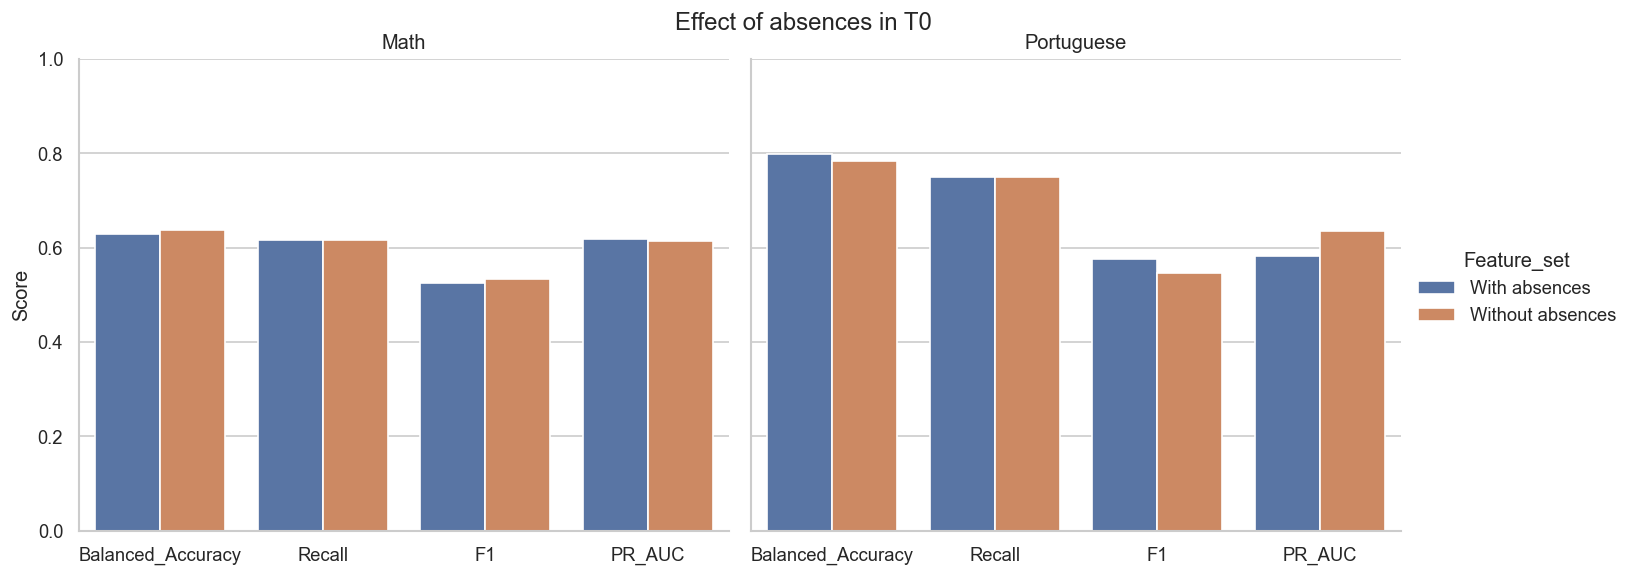

In [38]:
q14_rows = []
for course,frame in datasets.items():
    X_t0,y= scenario_xy(frame,"T0",)
    feature_sets = {"With absences": X_t0,"Without absences": X_t0.drop(columns=["absences"]),}
    for feature_set,X in feature_sets.items():
        model,selected,test_pos= (fit_q1_selected_model(course,"T0",X,y,))
        y_test= y.iloc[test_pos]
        prediction = model.predict(X.iloc[test_pos])
        probability= probability_of_risk(model,X.iloc[test_pos],)
        metrics = calculate_all_metrics(y_test,prediction,probability,)
        q14_rows.append({
            "Course": course,"Scenario":"T0","Model": selected["Model"],"Feature_set": feature_set,
            "Balanced_Accuracy": metrics["Balanced_Accuracy"],"Recall": metrics["Recall"],
            "F1": metrics["F1"],"PR_AUC": metrics["PR_AUC"],"FN": metrics["FN"],"TP": metrics["TP"],
        })

q14_results= pd.DataFrame(q14_rows)
print(q14_results.round(3).to_string(index=False))

q14_plot = q14_results.melt(
    id_vars=["Course","Feature_set",],value_vars=["Balanced_Accuracy","Recall","F1","PR_AUC",],
    var_name="Metric",value_name="Score",
)
g = sns.catplot(
    data=q14_plot,x="Metric",y="Score",hue="Feature_set",
    col="Course",kind="bar",height=5,aspect=1.2,
)
g.set_axis_labels("","Score",)
g.set_titles("{col_name}")
g.set(ylim=(0,1))
g.fig.suptitle("Effect of absences in T0",y=1.001,)
plt.show()

<div align="right">

## پرسش 15

</div>

In [39]:
q15_rows = []
for course,frame in datasets.items():
    for scenario in ["T0","T1","T2",]:
        X,y= scenario_xy(frame,scenario,)
        model,selected,test_pos = (fit_q1_selected_model(course,scenario,X,y,))
        importance= permutation_importance(
            model,X.iloc[test_pos],y.iloc[test_pos],scoring="average_precision",
            n_repeats=10,random_state=RANDOM_STATE,n_jobs=1,
        )
        importance_table = pd.DataFrame({
            "Course": course,"Scenario": scenario,"Model": selected["Model"],
            "Feature": X.columns,"Importance": (importance.importances_mean),
        })
        importance_table = (importance_table.sort_values("Importance",ascending=False,).reset_index(drop=True))
        importance_table["Rank"]= (np.arange(1,len(importance_table) +1,))
        q15_rows.append(importance_table)

q15_importance= pd.concat(q15_rows,ignore_index=True,)
q15_top_features = (q15_importance[q15_importance["Rank"] <=5].sort_values(["Course","Scenario","Rank",]))

print(q15_top_features.round(3).to_string(index=False))

    Course Scenario               Model   Feature  Importance  Rank
      Math       T0 Logistic Regression  failures       0.118     1
      Math       T0 Logistic Regression     goout       0.094     2
      Math       T0 Logistic Regression       age       0.047     3
      Math       T0 Logistic Regression       sex       0.035     4
      Math       T0 Logistic Regression      Mjob       0.027     5
      Math       T1 Logistic Regression        G1       0.537     1
      Math       T1 Logistic Regression      Walc       0.028     2
      Math       T1 Logistic Regression studytime       0.008     3
      Math       T1 Logistic Regression     goout       0.008     4
      Math       T1 Logistic Regression       age       0.007     5
      Math       T2 Logistic Regression        G2       0.525     1
      Math       T2 Logistic Regression        G1       0.043     2
      Math       T2 Logistic Regression      Walc       0.017     3
      Math       T2 Logistic Regression    famre

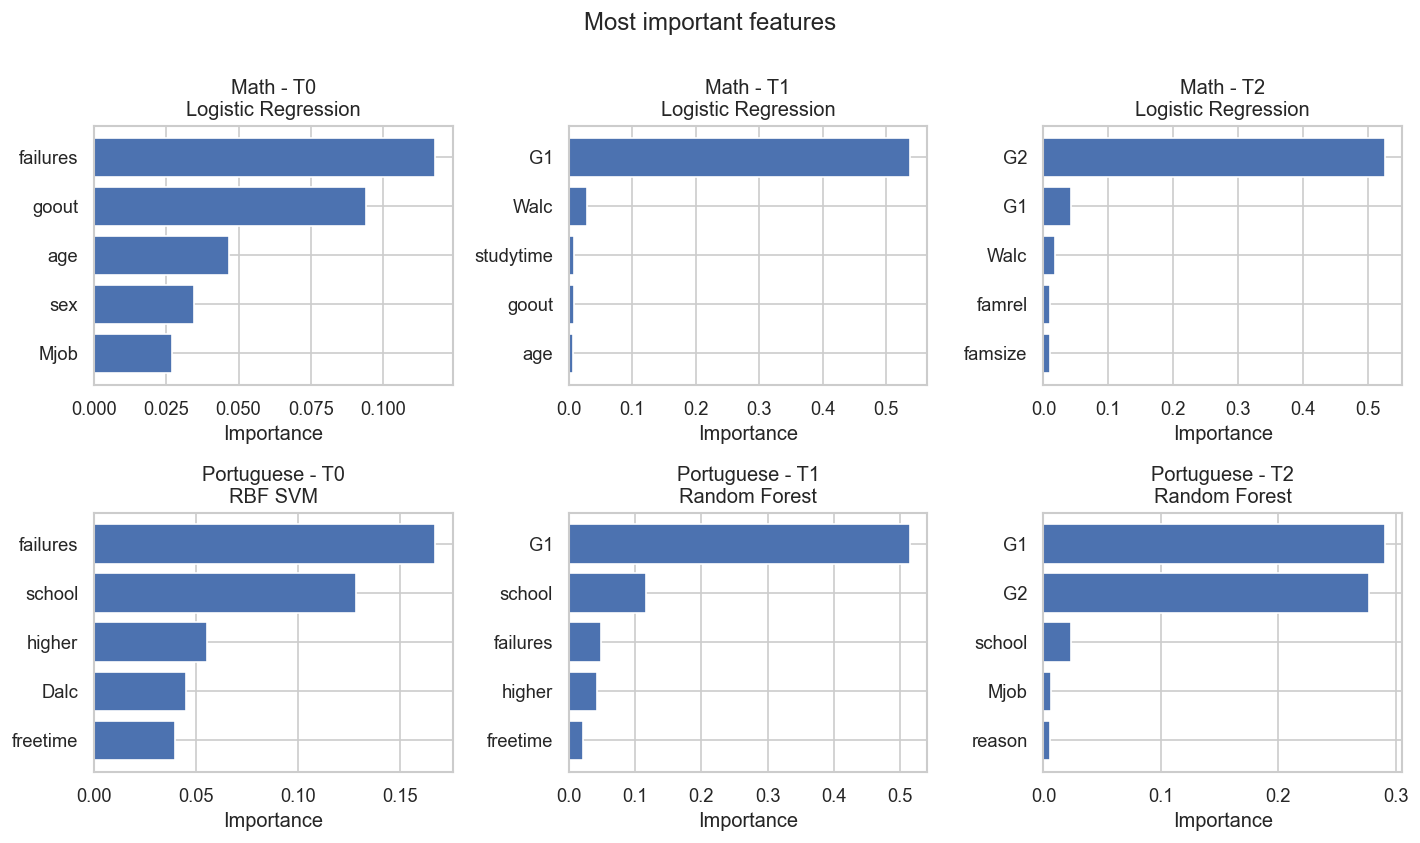

In [40]:
fig,axes = plt.subplots(2,3,figsize=(12,7),)
for row_index,course in enumerate(["Math","Portuguese",]):
    for column_index, scenario in enumerate(["T0","T1","T2",]):
        chart_data= (q15_top_features[(q15_top_features["Course"]== course)& (q15_top_features["Scenario"]== scenario)].sort_values("Importance",ascending=True,))
        ax= axes[row_index,column_index,]
        ax.barh(chart_data["Feature"],chart_data["Importance"],)
        model_name= (chart_data["Model"].iloc[0])
        ax.set_title(f"{course} - {scenario}\n" f"{model_name}")
        ax.set_xlabel("Importance")
        ax.set_ylabel("")

fig.suptitle("Most important features",y=1.001,)
plt.tight_layout()
plt.show()

<div align="right">

## پرسش 16

</div>

In [41]:
q16_rows= []
for course, frame in datasets.items():
    for scenario in ["T0","T1","T2",]:
        selected_model= best_by_scenario[(best_by_scenario["Course"]== course)& ( best_by_scenario["Scenario"]==scenario)].iloc[0]["Model"]
        predictions = (q1_predictions_df[
                (q1_predictions_df["Course"]== course)& (q1_predictions_df["Scenario"]== scenario)& (q1_predictions_df["Model"]==selected_model)]
            .sort_values("Student_position").reset_index(drop=True).copy()
        )
        positions= (predictions["Student_position"].astype(int).to_numpy())
        student_data =(frame.iloc[positions].reset_index(drop=True).copy())
        analysis_table= pd.concat([predictions,student_data,],axis=1,)
        analysis_table["Error_Type"] = (np.select(
                [(analysis_table["Actual_Risk"]== 1)& (analysis_table["Predicted_Risk"]== 0),
                    (analysis_table["Actual_Risk"]== 0)& (analysis_table["Predicted_Risk"]== 1),],
                ["False Negative","False Positive",],default="Correct",))
        q16_rows.append(analysis_table)

q16_all_predictions = pd.concat(q16_rows,ignore_index=True,)
q16_errors= q16_all_predictions[q16_all_predictions["Error_Type"].isin(["False Negative","False Positive",])].copy()
q16_error_profile = (q16_errors.groupby(["Course","Scenario","Error_Type",]).agg(
        Count=("Error_Type","size",),
        Mean_probability=("Risk_probability","mean",),Mean_G1=("G1","mean",),Mean_G2=("G2","mean",),Mean_G3=( "G3","mean",),
        Mean_failures=("failures","mean",),Mean_absences=("absences","mean",),Mean_studytime=("studytime","mean",),
    ).reset_index()
)
print(q16_error_profile.round(3).to_string(index=False))

    Course Scenario     Error_Type  Count  Mean_probability  Mean_G1  Mean_G2  Mean_G3  Mean_failures  Mean_absences  Mean_studytime
      Math       T0 False Negative     10             0.307    8.200    7.800    7.100          0.200          6.100           2.400
      Math       T0 False Positive     19             0.656   13.158   13.316   13.368          0.158          5.895           1.737
      Math       T1 False Negative      4             0.267    9.000    8.000    7.750          0.000          8.000           2.500
      Math       T1 False Positive      5             0.686    9.600   11.000   11.600          0.000          6.600           1.600
      Math       T2 False Positive      3             0.805    9.333    9.000   10.667          0.000          6.000           1.333
Portuguese       T0 False Negative      5             0.356    7.800    8.000    6.800          0.200          2.000           1.800
Portuguese       T0 False Positive     17             0.590   10.529 

<div align="right">

## پرسش 17

</div>

In [42]:
def q17_group_metrics(data,Property):
    rows= []
    for group_name,group_data in data.groupby(Property,observed=True,):
        y_true= group_data["Actual_Risk"].to_numpy(dtype=int)
        y_pred= group_data["Predicted_Risk"].to_numpy(dtype=int)
        TN,FP, FN,TP = confusion_matrix(y_true,y_pred,labels=[0,1],).ravel()
        rows.append({
            "Property": Property,"Group": str(group_name),
            "Accuracy": accuracy_score(y_true,y_pred,),
            "TPR": (TP/ (TP + FN) if (TP + FN) > 0 else np.nan),
            "FPR": (FP /(FP + TN) if (FP+ TN) > 0 else np.nan),
        })
    return pd.DataFrame(rows)

def Gap_summary(group_table):
    def gap(column): 
        values = group_table[column].dropna()
        if len(values)< 2:
            return np.nan
        return (values.max()- values.min())
    tpr_gap= gap("TPR")
    fpr_gap =gap("FPR")
    return {"Accuracy_gap": gap("Accuracy"),"TPR_gap": tpr_gap,"FPR_gap":fpr_gap,}

q17_selected_rows = []
for course,frame in datasets.items():
    for scenario in ["T0","T1","T2",]:
        selected_model = (best_by_scenario[
            (best_by_scenario["Course"]== course) &(best_by_scenario["Scenario"]== scenario)
            ].iloc[0]["Model"]
        )
        predictions = ( q1_predictions_df[
                (q1_predictions_df["Course"]== course)& (q1_predictions_df["Scenario"] == scenario)& (q1_predictions_df["Model"]== selected_model)
            ].sort_values("Student_position").reset_index(drop=True).copy()
        )
        positions= (predictions["Student_position"].astype(int).to_numpy())
        metadata = (frame.iloc[positions][["sex","address","school",]].reset_index(drop=True))
        q17_selected_rows.append(pd.concat([predictions,metadata,],axis=1,))

q17_selected_predictions = (pd.concat(q17_selected_rows,ignore_index=True,))

q17_group_rows = []
q17_gap_rows = []
for course in ["Math","Portuguese",]:
    for scenario in ["T0","T1","T2",]:
        subset = (q17_selected_predictions[
                (q17_selected_predictions["Course"]== course)& (q17_selected_predictions["Scenario"]==scenario)
            ])
        model_name = (subset["Model"].iloc[0])
        for Property in ["sex","address","school",]:
            group_table = (q17_group_metrics(subset,Property,))
            group_table.insert(0,"Course",course,)
            group_table.insert(1,"Scenario",scenario,)
            group_table.insert(2,"Model",model_name,)
            q17_group_rows.append(group_table)
            q17_gap_rows.append({
                "Course": course,"Scenario": scenario,
                "Model": model_name,"Property": Property,
                **Gap_summary(group_table),
            })

q17_group_results = pd.concat(q17_group_rows,ignore_index=True,)
q17_gap_results = pd.DataFrame(q17_gap_rows)

print("Performance for individual groups:")
print(q17_group_results[["Course","Scenario","Property","Group","Accuracy","TPR","FPR",]]
    .round(3).to_string(index=False)
)

Performance for individual groups:
    Course Scenario Property Group  Accuracy   TPR   FPR
      Math       T0      sex     F     0.571 0.688 0.500
      Math       T0      sex     M     0.703 0.500 0.222
      Math       T0  address     R     0.562 0.800 0.545
      Math       T0  address     U     0.651 0.571 0.310
      Math       T0   school    GP     0.609 0.565 0.370
      Math       T0   school    MS     0.800 1.000 0.286
      Math       T1      sex     F     0.857 0.875 0.154
      Math       T1      sex     M     0.919 0.800 0.037
      Math       T1  address     R     0.812 0.800 0.182
      Math       T1  address     U     0.905 0.857 0.071
      Math       T1   school    GP     0.870 0.826 0.109
      Math       T1   school    MS     1.000 1.000 0.000
      Math       T2      sex     F     0.976 1.000 0.038
      Math       T2      sex     M     0.946 1.000 0.074
      Math       T2  address     R     0.938 1.000 0.091
      Math       T2  address     U     0.968 1.000 0.

In [43]:
print("Groupe gaps:")
print(q17_gap_results[["Course","Scenario","Property","TPR_gap","FPR_gap",]]
    .round(3).to_string(index=False)
)

Groupe gaps:
    Course Scenario Property  TPR_gap  FPR_gap
      Math       T0      sex    0.188    0.278
      Math       T0  address    0.229    0.236
      Math       T0   school    0.435    0.084
      Math       T1      sex    0.075    0.117
      Math       T1  address    0.057    0.110
      Math       T1   school    0.174    0.109
      Math       T2      sex    0.000    0.036
      Math       T2  address    0.000    0.043
      Math       T2   school    0.000    0.065
Portuguese       T0      sex    0.208    0.126
Portuguese       T0  address    0.208    0.135
Portuguese       T0   school    0.055    0.429
Portuguese       T1      sex    0.333    0.003
Portuguese       T1  address    0.083    0.099
Portuguese       T1   school    0.132    0.200
Portuguese       T2      sex    0.000    0.064
Portuguese       T2  address    0.000    0.042
Portuguese       T2   school    0.000    0.142


<div align="right">

## پرسش 18

</div>

In [44]:
DELETED_FEATURES =["sex","address","school",]
q18_performance_rows = []
q18_fairness_rows = []
def q18_max_gap(gaps):
    values= [gaps["TPR_gap"],gaps["FPR_gap"],]
    values= [value for value in values if pd.notna(value)]
    return (max(values) if values else np.nan)

for course, frame in datasets.items():
    for scenario in ["T0","T1","T2",]:
        selected_model = (best_by_scenario[
                (best_by_scenario["Course"]== course)& (best_by_scenario["Scenario"]== scenario)
            ].iloc[0]["Model"]
        )

        full_data = (
            q17_selected_predictions[
                (q17_selected_predictions["Course"]== course)& ( q17_selected_predictions["Scenario"]== scenario)
            ].reset_index(drop=True).copy()
        )
        full_metrics = (calculate_all_metrics(full_data["Actual_Risk"], full_data["Predicted_Risk"],full_data["Risk_probability"],))

        X,y = scenario_xy(frame,scenario,)
        X_reduced = X.drop(columns=DELETED_FEATURES,errors="ignore",)
        (reduced_model,selected,test_pos,) = fit_q1_selected_model(course,scenario,X_reduced,y,)
        reduced_prediction= (reduced_model.predict(X_reduced.iloc[test_pos]))
        reduced_probability= (probability_of_risk(reduced_model,X_reduced.iloc[test_pos],))
        y_test= (y.iloc[test_pos].to_numpy(dtype=int))
        reduced_metrics= (calculate_all_metrics(y_test,reduced_prediction,reduced_probability,))

        for configuration,metrics in [("Full",full_metrics,),("Sensitive removed",reduced_metrics,),]:
            q18_performance_rows.append({
                "Course": course,"Scenario": scenario,"Model": selected_model,
                "Configuration": configuration,"Recall": metrics["Recall"],"F1": metrics["F1"],
            })
        reduced_metadata= (frame.iloc[test_pos][DELETED_FEATURES].reset_index(drop=True))
        reduced_data= pd.concat([pd.DataFrame({"Actual_Risk": y_test,"Predicted_Risk": (reduced_prediction),}),reduced_metadata,],axis=1,)
        evaluation_tables = [("Full",full_data,),("Sensitive removed",reduced_data,),]
        for (configuration,evaluation_data,) in evaluation_tables:
            for Property in (DELETED_FEATURES):
                group_table= (q17_group_metrics(evaluation_data,Property,))
                gaps= Gap_summary(group_table)
                q18_fairness_rows.append({
                    "Course": course,"Scenario": scenario,"Model": selected_model,
                    "Configuration": (configuration),"Property": Property,"Max_gap": (q18_max_gap(gaps)),
                })

q18_performance = pd.DataFrame(q18_performance_rows)
q18_fairness =pd.DataFrame(q18_fairness_rows)

In [45]:
performance_metrics = ["Recall","F1",]
performance_keys = ["Course","Scenario","Model",]
full_performance = (q18_performance[q18_performance["Configuration"]== "Full"]
    .set_index(performance_keys )[performance_metrics].add_prefix("Full_")
)
removed_performance = (q18_performance[q18_performance["Configuration"]== "Sensitive removed"]
    .set_index(performance_keys)[performance_metrics].add_prefix("Removed_")
)
q18_performance_comparison = (full_performance.join(removed_performance).reset_index())

for metric in performance_metrics:
    q18_performance_comparison[f"Delta_{metric}"] = (q18_performance_comparison[f"Removed_{metric}"]- q18_performance_comparison[f"Full_{metric}"])

fairness_metrics = ["Max_gap"]
fairness_keys = ["Course","Scenario","Model","Property",]
full_fairness = (q18_fairness[q18_fairness["Configuration"]== "Full"].set_index(fairness_keys)[fairness_metrics].add_prefix("Full_"))
removed_fairness = (q18_fairness[q18_fairness["Configuration"]== "Sensitive removed"].set_index(fairness_keys)[fairness_metrics].add_prefix("Removed_"))
q18_fairness_comparison = ( full_fairness.join(removed_fairness).reset_index())
for metric in fairness_metrics:
    q18_fairness_comparison[f"Delta_{metric}"] = (q18_fairness_comparison[f"Removed_{metric}"]- q18_fairness_comparison[f"Full_{metric}"])

print("Performance before and after delete sensitive features:")
print(q18_performance_comparison[[
        "Course","Scenario","Model","Full_F1","Removed_F1","Delta_F1","Full_Recall","Removed_Recall","Delta_Recall",
    ]].round(3).to_string(index=False))

print("\nFairness before and after delete sensitive features:")
print(q18_fairness_comparison[[
        "Course","Scenario","Property","Full_Max_gap","Removed_Max_gap","Delta_Max_gap",
    ]].round(3).to_string(index=False))

Performance before and after delete sensitive features:
    Course Scenario               Model  Full_F1  Removed_F1  Delta_F1  Full_Recall  Removed_Recall  Delta_Recall
      Math       T0 Logistic Regression    0.525       0.567     0.042        0.615           0.654         0.038
      Math       T1 Logistic Regression    0.830       0.885     0.054        0.846           0.885         0.038
      Math       T2 Logistic Regression    0.945       0.945     0.000        1.000           1.000         0.000
Portuguese       T0             RBF SVM    0.577       0.435    -0.142        0.750           0.500        -0.250
Portuguese       T1       Random Forest    0.762       0.756    -0.006        0.800           0.850         0.050
Portuguese       T2       Random Forest    0.851       0.826    -0.025        1.000           0.950        -0.050

Fairness before and after delete sensitive features:
    Course Scenario Property  Full_Max_gap  Removed_Max_gap  Delta_Max_gap
      Math       

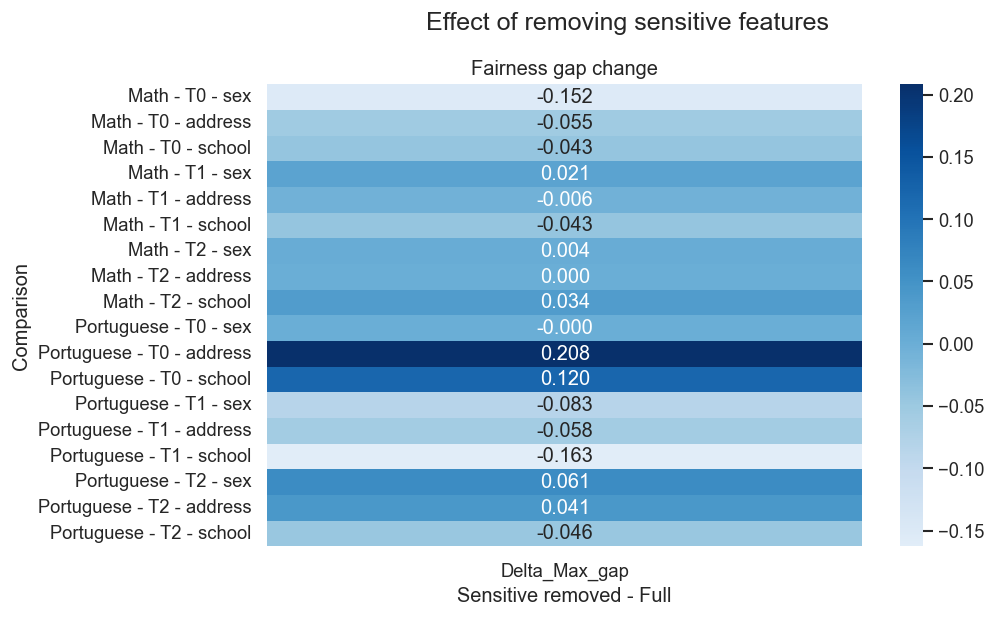

In [46]:
q18_fairness_plot = (q18_fairness_comparison[["Course","Scenario","Property","Delta_Max_gap",]].copy())
q18_fairness_plot["Comparison"] = (q18_fairness_plot[ "Course"]+ " - "+ q18_fairness_plot["Scenario"]+ " - "+ q18_fairness_plot["Property"])
fairness_heatmap = (q18_fairness_plot.set_index("Comparison")[["Delta_Max_gap"]])
fig, axes = plt.subplots(1,1,figsize=(8,5),)

sns.heatmap(fairness_heatmap,annot=True,fmt=".3f",center=0,cmap="Blues",)
axes.set_title("Fairness gap change")
axes.set_xlabel("Sensitive removed - Full")
fig.suptitle("Effect of removing sensitive features",y=1.001,fontsize=15,)
plt.show()

<div align="right">

## پرسش 19

</div>

In [47]:
q19_rows= []
transfer_directions = [("Math", "Portuguese"),("Portuguese", "Math"),]
for train_course,test_course in transfer_directions:
    train_frame = datasets[train_course]
    test_frame = datasets[test_course]
    (train_pos,validation_pos,_,) = course_splits[train_course]
    train_validation_pos = np.concatenate([train_pos,validation_pos,])
    (_,_,test_pos,) =course_splits[test_course]
    for scenario in ["T0","T1","T2",]:
        source_selected = best_by_scenario[
            (best_by_scenario["Course"]== train_course)& (best_by_scenario["Scenario"]== scenario)
        ].iloc[0]
        target_selected = best_by_scenario[
            (best_by_scenario["Course"]== test_course)& (best_by_scenario["Scenario"]== scenario)
        ].iloc[0]
        X_train_course, y_train_course = scenario_xy(train_frame,scenario,)
        X_test_course, y_test_course = scenario_xy(test_frame,scenario,)
        estimator = (estimator_from_selected_configuration(source_selected["Model"],source_selected["Selected_parameters"],))
        transfer_model = Pipeline([("preprocess",preprocessor(X_train_course.iloc[train_validation_pos]),),("model",estimator,),])
        transfer_model.fit(X_train_course.iloc[train_validation_pos],y_train_course.iloc[train_validation_pos],)
        transfer_prediction = (transfer_model.predict(X_test_course.iloc[test_pos]))
        transfer_probability= (probability_of_risk(transfer_model,X_test_course.iloc[test_pos],))
        transfer_metrics = (calculate_all_metrics( y_test_course.iloc[test_pos],transfer_prediction,transfer_probability,))
        target_predictions = (q1_predictions_df[
                (q1_predictions_df["Course"] ==test_course)&(q1_predictions_df["Scenario"] == scenario)& (q1_predictions_df["Model"]== target_selected["Model"])
            ].sort_values("Student_position"))
        target_metrics = (
            calculate_all_metrics(target_predictions["Actual_Risk"],target_predictions["Predicted_Risk"],target_predictions["Risk_probability"],)
        )
        q19_rows.append({
            "Train_course": train_course,"Test_course": test_course,"Direction": (f"{train_course} -> " f"{test_course}"),
            "Scenario": scenario,"Cross_model": (source_selected["Model"]),"Target_model": (target_selected["Model"]),
            "Cross_Balanced_Accuracy": (transfer_metrics["Balanced_Accuracy"]),
            "Target_Balanced_Accuracy": ( target_metrics["Balanced_Accuracy"]),
            "Cross_Recall": (transfer_metrics["Recall"]),"Target_Recall": (target_metrics["Recall"]),
            "Cross_F1": (transfer_metrics["F1"]),"Target_F1": (target_metrics["F1"]),
        })

q19_results = pd.DataFrame(q19_rows)
print("Cross and Target results:")
print(q19_results[[
        "Direction","Scenario","Cross_model","Target_model",
        "Cross_Balanced_Accuracy","Target_Balanced_Accuracy",
        "Cross_Recall","Target_Recall","Cross_F1","Target_F1",
    ]].round(3).to_string(index=False)
)

Cross and Target results:
         Direction Scenario         Cross_model        Target_model  Cross_Balanced_Accuracy  Target_Balanced_Accuracy  Cross_Recall  Target_Recall  Cross_F1  Target_F1
Math -> Portuguese       T0 Logistic Regression             RBF SVM                    0.564                     0.798         0.700          0.750     0.289      0.577
Math -> Portuguese       T1 Logistic Regression       Random Forest                    0.893                     0.873         0.950          0.800     0.667      0.762
Math -> Portuguese       T2 Logistic Regression       Random Forest                    0.870                     0.968         0.850          1.000     0.694      0.851
Portuguese -> Math       T0             RBF SVM Logistic Regression                    0.616                     0.628         0.308          0.615     0.421      0.525
Portuguese -> Math       T1       Random Forest Logistic Regression                    0.664                     0.876         0.

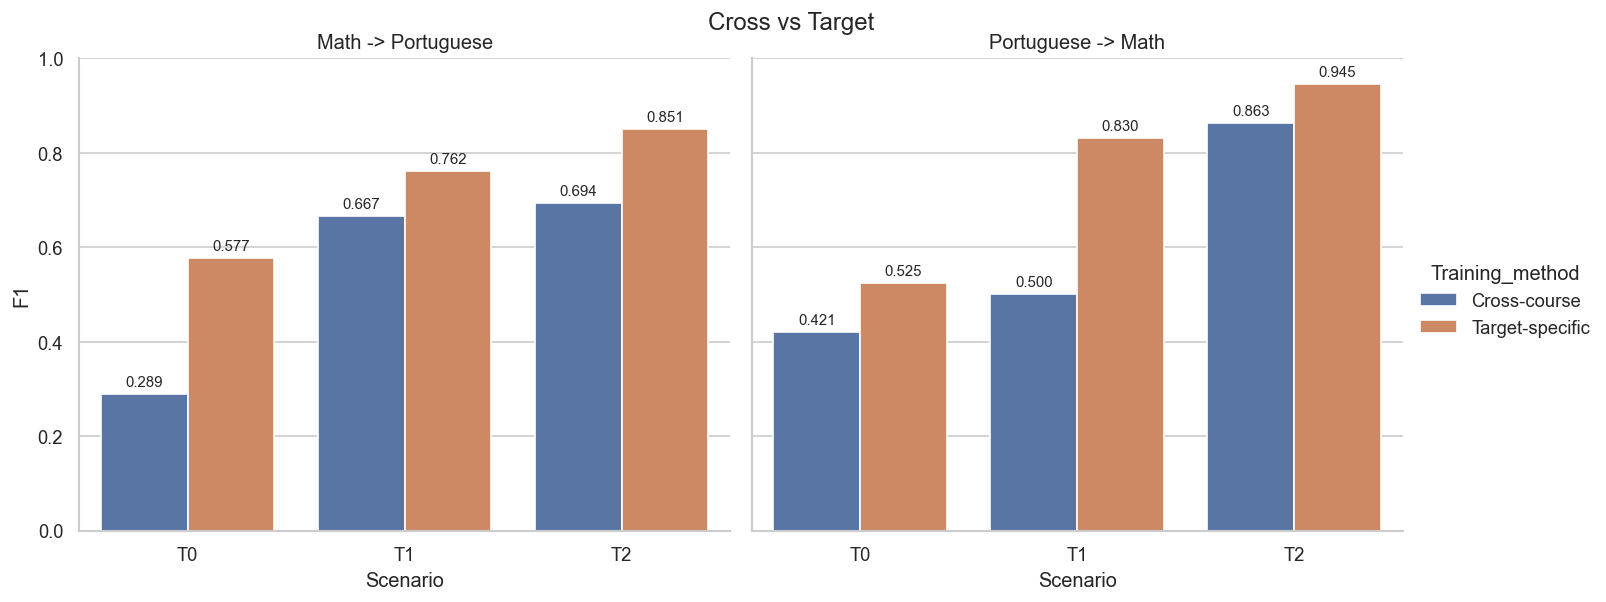

In [48]:
q19_plot = q19_results.melt(
    id_vars=["Direction","Scenario",],value_vars=["Cross_F1","Target_F1",],
    var_name="Training_method",value_name="F1",
)
q19_plot["Training_method"] = (q19_plot["Training_method"].replace({"Cross_F1": "Cross-course","Target_F1": "Target-specific",}))
g = sns.catplot(
    data=q19_plot,x="Scenario",y="F1",hue="Training_method",col="Direction",kind="bar",height=5,aspect=1.2,
)
for ax in g.axes.flat:
    for c in ax.containers:
        ax.bar_label(c,padding=3,fmt="%.3f",fontsize=9,)
g.set_axis_labels("Scenario","F1",)
g.set_titles("{col_name}")
g.set(ylim=(0, 1))
g.fig.suptitle("Cross vs Target",y=1.001,)
plt.show()

<div align="right">

## پرسش 20

</div>

In [49]:
def q20_combined_data(scenario):
    X_train_parts = []
    y_train_parts= []
    X_validation_parts = []
    y_validation_parts =[]
    X_test_parts = []
    y_test_parts = []
    test_course_parts=[]
    for course, frame in datasets.items():
        X, y= scenario_xy(frame,scenario,)
        X= X.copy()
        X["course"] = course
        (train_pos,validation_pos,test_pos,)= course_splits[course]
        X_train_parts.append(X.iloc[train_pos])
        y_train_parts.append(y.iloc[train_pos])
        X_validation_parts.append(X.iloc[validation_pos])
        y_validation_parts.append(y.iloc[validation_pos])
        X_test_parts.append(X.iloc[test_pos])
        y_test_parts.append(y.iloc[test_pos])
        test_course_parts.append(pd.Series([course]* len(test_pos)))

    return (
        pd.concat(X_train_parts,ignore_index=True,),pd.concat(y_train_parts,ignore_index=True,),
        pd.concat(X_validation_parts,ignore_index=True,),pd.concat(y_validation_parts,ignore_index=True,),
        pd.concat(X_test_parts,ignore_index=True,),pd.concat(y_test_parts,ignore_index=True,),
        pd.concat(test_course_parts,ignore_index=True,),
    )
q20_summary_rows = []
q20_course_rows = []
for scenario in ["T0","T1","T2",]:
    (X_train,y_train,X_validation,y_validation,X_test,y_test,test_course,) = q20_combined_data(scenario)
    best_joint = None
    for (family,parameters,estimator,) in candidate_models():
        validation_model = Pipeline([("preprocess",preprocessor(X_train),),("model",clone(estimator),),])
        validation_model.fit(X_train,y_train,)
        validation_prediction = (validation_model.predict(X_validation))
        validation_probability = (probability_of_risk(validation_model,X_validation,))
        validation_metrics = (calculate_all_metrics(y_validation,validation_prediction,validation_probability,))
        rank = validation_rank(validation_metrics)
        if (best_joint is None or rank > best_joint["rank"]):
            best_joint = {
                "rank": rank,"family": family,"parameters": parameters,
                "estimator": clone(estimator),"validation_metrics": (validation_metrics),
            }
    X_train_validation = pd.concat([X_train,X_validation,],ignore_index=True,)
    y_train_validation = pd.concat([y_train,y_validation,],ignore_index=True,)
    joint_model= Pipeline([("preprocess",preprocessor(X_train_validation),),("model",clone(best_joint["estimator"]),),])
    joint_model.fit(X_train_validation,y_train_validation,)
    joint_prediction = (joint_model.predict(X_test))
    joint_probability= (probability_of_risk(joint_model,X_test,))
    joint_metrics = (calculate_all_metrics(y_test,joint_prediction,joint_probability,))
    prediction_parts= []
    for course in ["Math","Portuguese",]:
        separate_selected = (best_by_scenario[
                (best_by_scenario["Course"]== course)&(best_by_scenario["Scenario"]== scenario)
            ].iloc[0]
        )
        separate_predictions = (q1_predictions_df[
                (q1_predictions_df["Course"]==course)& (q1_predictions_df["Scenario"]== scenario)& (q1_predictions_df["Model"]== separate_selected["Model"])
            ].sort_values("Student_position").copy()
        )
        prediction_parts.append(separate_predictions)
        course_mask = (test_course.to_numpy()== course)
        joint_course_metrics = (
            calculate_all_metrics(
                y_test.to_numpy()[course_mask],joint_prediction[course_mask],joint_probability[course_mask],
            )
        )
        course_metrics = (
            calculate_all_metrics(
                separate_predictions["Actual_Risk"],separate_predictions["Predicted_Risk"],separate_predictions["Risk_probability"],
            )
        )
        q20_course_rows.append({
            "Course": course,"Scenario": scenario,
            "Joint_model": (best_joint["family"]),"Separate_model": (separate_selected["Model"]),
            "Joint_F1":(joint_course_metrics["F1"]),"Separate_F1": (course_metrics["F1"]),
            "Joint_Recall": (joint_course_metrics["Recall"]),"Separate_Recall": (course_metrics["Recall"]),
        })
    Predictions_all = pd.concat(prediction_parts,ignore_index=True,)
    separate_metrics = (
        calculate_all_metrics(
            Predictions_all["Actual_Risk"],Predictions_all["Predicted_Risk"],Predictions_all["Risk_probability"],
        )
    )

    math_model = (
        best_by_scenario[
            (best_by_scenario["Course"]== "Math")& (best_by_scenario["Scenario"]== scenario)
        ].iloc[0]["Model"]
    )
    portuguese_model = (
        best_by_scenario[
            (best_by_scenario["Course"]== "Portuguese")& (best_by_scenario["Scenario"]==scenario)
        ].iloc[0]["Model"]
    )
    q20_summary_rows.append({
        "Scenario": scenario,"Joint_model": (best_joint["family"]),
        "Joint_parameters": json.dumps(best_joint["parameters"],sort_keys=True,),
        "Joint_validation_F1":(best_joint["validation_metrics"]["F1"]),
        "Math_model": (math_model),"Portuguese_model": (portuguese_model),
        "Joint_Balanced_Accuracy": (joint_metrics["Balanced_Accuracy"]),"Separate_Balanced_Accuracy": (separate_metrics["Balanced_Accuracy"]),
        "Joint_Recall": (joint_metrics["Recall"]),"Separate_Recall": ( separate_metrics["Recall"]),
        "Joint_F1": (joint_metrics["F1"]),"Separate_F1": (separate_metrics["F1"]),
    })
q20_summary = pd.DataFrame(q20_summary_rows)
q20_by_course = pd.DataFrame(q20_course_rows)

In [50]:
print("Joint vs separate results:")
print(q20_summary[[
        "Scenario","Joint_model","Math_model","Portuguese_model",
        "Joint_Balanced_Accuracy","Separate_Balanced_Accuracy",
        "Joint_Recall","Separate_Recall","Joint_F1","Separate_F1",
    ]].round(3).to_string(index=False)
)

print("Results for each course:")
print(q20_by_course[[
        "Course","Scenario","Joint_model","Separate_model",
        "Joint_F1","Separate_F1","Joint_Recall","Separate_Recall",
    ]].round(3).to_string(index=False)
)

Joint vs separate results:
Scenario   Joint_model          Math_model Portuguese_model  Joint_Balanced_Accuracy  Separate_Balanced_Accuracy  Joint_Recall  Separate_Recall  Joint_F1  Separate_F1
      T0 Random Forest Logistic Regression          RBF SVM                    0.684                       0.727         0.478            0.674     0.512        0.549
      T1 Random Forest Logistic Regression    Random Forest                    0.898                       0.879         0.870            0.826     0.816        0.800
      T2 Random Forest Logistic Regression    Random Forest                    0.948                       0.969         0.957            1.000     0.880        0.902
Results for each course:
    Course Scenario   Joint_model      Separate_model  Joint_F1  Separate_F1  Joint_Recall  Separate_Recall
      Math       T0 Random Forest Logistic Regression     0.560        0.525         0.538            0.615
Portuguese       T0 Random Forest             RBF SVM     0.444 

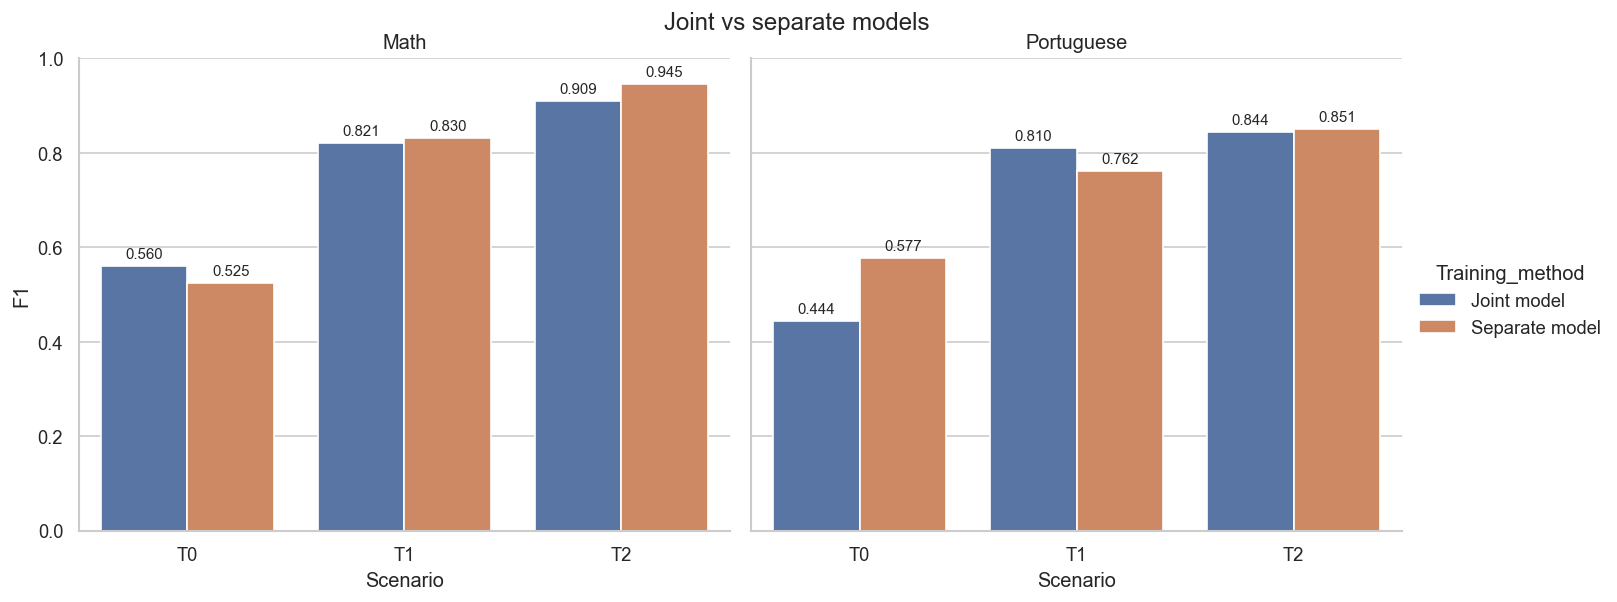

In [51]:
q20_plot = q20_by_course.melt(
    id_vars=["Course","Scenario",],value_vars=["Joint_F1","Separate_F1",],
    var_name="Training_method",value_name="F1",
)
q20_plot["Training_method"] = (q20_plot["Training_method"]
    .replace({"Joint_F1": "Joint model","Separate_F1": "Separate model",})
)
g = sns.catplot(
    data=q20_plot,x="Scenario",y="F1",hue="Training_method",
    col="Course",kind="bar",height=5,aspect=1.2,
)
for ax in g.axes.flat:
    for c in ax.containers:
        ax.bar_label(c,padding=3,fmt="%.3f",fontsize=9,)

g.set_axis_labels("Scenario","F1",)
g.set_titles("{col_name}")
g.set(ylim=(0, 1))
g.fig.suptitle("Joint vs separate models",y=1.001,)
plt.show()